# Mi primera wPINN: choque móvil

Ley de conservación de Burgers en 2D:

$$u_t + \partial_x\Big(\tfrac{u^2}{2}\Big) + \partial_y\Big(\tfrac{u^2}{2}\Big) = 0, \qquad (x,y) \in [-1,1]^2, \quad t \in [0, 0.5]$$

con dato inicial $u_0 = 1$ si $x \le 0$ y $u_0 = 0$ si $x > 0$.

La solución es un choque que viaja a la derecha con velocidad de Rankine-Hugoniot
$s = \frac{H(1)-H(0)}{1-0} = \frac12$, es decir el salto está en $x = t/2$.

**Idea de la wPINN.** Como $u$ salta, no se puede usar el residual fuerte. En su lugar
se usa la desigualdad de entropía de Kruzhkov: para toda constante $c$ y toda función
test $\varphi \ge 0$,

$$R(c) = \int_0^T\!\!\int_\Omega \Big( \varphi\,\mathrm{sign}(u-c)\,u_t - Q(u,c)\,(\varphi_x + \varphi_y) \Big)\,dx\,dy\,dt \;\le\; 0,
\qquad Q(u,c) = \mathrm{sign}(u-c)\big(H(u) - H(c)\big).$$

La función test $\varphi$ es **otra red neuronal** que intenta romper esa desigualdad
(maximiza), y la red $u$ intenta cumplirla (minimiza).

## 1. Montaje del método

Todo lo que se necesita para entrenar: el problema, las redes, los puntos, el residual débil y el bucle min-max. Las secciones siguientes son experimentos que reusan estas piezas.

### 1.1 Librerías y configuración

In [1]:
import copy
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils import parameters_to_vector, vector_to_parameters   # pesos <-> un solo vector (para el punto de silla)
import matplotlib.pyplot as plt

# Semilla fija para que dos corridas den lo mismo.
torch.manual_seed(0)
np.random.seed(0)

# GPU si hay, si no CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


### 1.2 El problema: choque móvil

In [2]:
# Dominio: x e y en [-1, 1], tiempo en [0, T].
x_min, x_max = -1.0, 1.0
y_min, y_max = -1.0, 1.0
T = 1

# Volumen del dominio espacio-temporal |D| = 2 * 2 * 0.5 = 2.
# Sirve para pasar de un promedio Monte Carlo a una integral.
volume = (x_max - x_min) * (y_max - y_min) * T

# Flujo de Burgers. Es el mismo en x y en y.
def flux(u):
    return 0.5 * u**2

# Dato inicial: 1 a la izquierda de x = 0, 0 a la derecha. No depende de y.
def initial_condition(x):
    return torch.where(x <= 0.0, 1.0, 0.0)

# Velocidad del choque (Rankine-Hugoniot): s = (H(1) - H(0)) / (1 - 0) = 1/2.
shock_speed = 0.5

# Solución exacta en numpy, sólo para comparar al final.
def exact_solution(x, t):
    return np.where(x <= shock_speed * t, 1.0, 0.0)

### 1.3 Las dos redes

- $u_\theta(x,y,t)$: la solución. 6 capas ocultas de 20 neuronas (como el paper).
- $\xi_\eta(x,y,t)$: la red de la función test. 4 capas de 10, más pequeña a propósito.

In [3]:
class Sine(nn.Module):
    # Activación seno. PyTorch no la trae como capa, así que la defino aquí.
    # De Ryck et al. la usan en la red u; sirve para uno de los experimentos de arquitectura.
    def forward(self, x):
        return torch.sin(x)


def build_network(n_hidden_layers, width, activation=nn.Tanh):
    # Red totalmente conectada: entra (x, y, t), sale un número.
    # Las dos redes del método son iguales salvo el tamaño, por eso una sola función.
    # activation es la CLASE (nn.Tanh, Sine, ...), no una instancia: se crea una por capa.
    layers = [nn.Linear(3, width), activation()]
    for _ in range(n_hidden_layers - 1):
        layers += [nn.Linear(width, width), activation()]
    layers.append(nn.Linear(width, 1))  # sin activación al final: la salida puede valer cualquier cosa
    return nn.Sequential(*layers).to(device)


# Red de la función test: sale xi. Luego phi = ventana * softplus(xi).
# Una sola para todo el notebook: se reinicia en cada época, así que da igual reusarla.
# (train_wpinn la reconstruye si se le pide otro tamaño.)
test_network = build_network(n_hidden_layers=4, width=10)

# La red solución NO se crea aquí: train_wpinn crea una nueva en cada entrenamiento,
# así cada corrida empieza desde cero.

# No normalizo las entradas: x e y ya están en [-1, 1] y t en [0, 0.5],
# así que las tanh no se saturan.
print(build_network(n_hidden_layers=6, width=20))
print(test_network)

Sequential(
  (0): Linear(in_features=3, out_features=20, bias=True)
  (1): Tanh()
  (2): Linear(in_features=20, out_features=20, bias=True)
  (3): Tanh()
  (4): Linear(in_features=20, out_features=20, bias=True)
  (5): Tanh()
  (6): Linear(in_features=20, out_features=20, bias=True)
  (7): Tanh()
  (8): Linear(in_features=20, out_features=20, bias=True)
  (9): Tanh()
  (10): Linear(in_features=20, out_features=20, bias=True)
  (11): Tanh()
  (12): Linear(in_features=20, out_features=1, bias=True)
)
Sequential(
  (0): Linear(in_features=3, out_features=10, bias=True)
  (1): Tanh()
  (2): Linear(in_features=10, out_features=10, bias=True)
  (3): Tanh()
  (4): Linear(in_features=10, out_features=10, bias=True)
  (5): Tanh()
  (6): Linear(in_features=10, out_features=10, bias=True)
  (7): Tanh()
  (8): Linear(in_features=10, out_features=1, bias=True)
)


#### Diagrama de las redes

Cada columna es una capa: entrada $(x, y, t)$ en azul, capas ocultas en gris y salida en naranja.
Se dibujan a lo sumo 8 neuronas por capa; el ancho real va escrito debajo de cada columna y la
activación encima. Abajo está la red test: su salida $\xi$ se convierte en
$\varphi = \mathrm{softplus}(\xi)\,(1-x^2)(1-y^2)$.

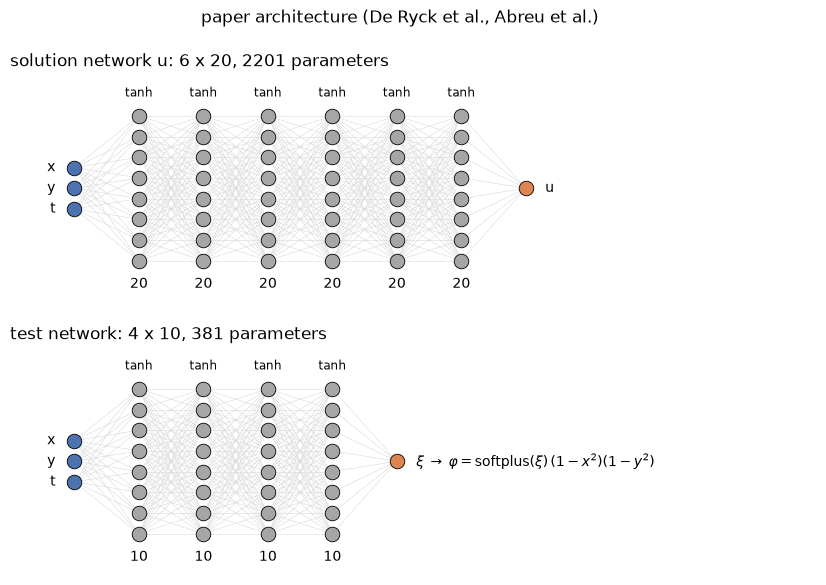

In [4]:
def count_parameters(network):
    # Número de pesos entrenables (matrices + sesgos).
    return sum(parameter.numel() for parameter in network.parameters())


def draw_network_row(ax, n_hidden_layers, width, activation_name, output_label, max_drawn_neurons=8):
    # Dibuja una red en un eje: una columna de círculos por capa.
    layer_sizes = [3] + [width] * n_hidden_layers + [1]
    last_layer = len(layer_sizes) - 1

    # Alturas de los círculos de cada columna, centradas en 0.
    neuron_heights = []
    for size in layer_sizes:
        n_drawn = min(size, max_drawn_neurons)
        neuron_heights.append(np.arange(n_drawn) - (n_drawn - 1) / 2)

    # Conexiones primero (zorder 1) para que queden debajo de los círculos.
    for k in range(last_layer):
        for y_left in neuron_heights[k]:
            for y_right in neuron_heights[k + 1]:
                ax.plot([k, k + 1], [y_left, y_right], color="0.85", linewidth=0.4, zorder=1)

    # Neuronas: el color dice el papel de la capa (entrada, oculta, salida).
    for k, heights in enumerate(neuron_heights):
        if k == 0:
            color = "#4C72B0"     # entrada
        elif k == last_layer:
            color = "#DD8452"     # salida
        else:
            color = "0.65"        # oculta
        ax.scatter(np.full(len(heights), k), heights, s=110, color=color,
                   edgecolor="black", linewidth=0.6, zorder=2)

    # Nombres de las entradas y de la salida.
    # [::-1] para que x quede arriba y t abajo (las alturas van de abajo hacia arriba).
    for y, name in zip(neuron_heights[0][::-1], ["x", "y", "t"]):
        ax.text(-0.3, y, name, ha="right", va="center")
    ax.text(last_layer + 0.3, 0, output_label, ha="left", va="center")

    # Ancho real debajo y activación encima de cada capa oculta.
    half_height = (min(width, max_drawn_neurons) - 1) / 2
    for k in range(1, last_layer):
        ax.text(k, -half_height - 0.8, str(width), ha="center", va="top")
        ax.text(k, half_height + 0.8, activation_name, ha="center", va="bottom", fontsize="small")
    ax.set_ylim(-half_height - 2.0, half_height + 2.0)
    ax.axis("off")


def draw_architecture(title, u_hidden_layers=6, u_width=20, u_activation=nn.Tanh,
                      test_hidden_layers=4, test_width=10):
    # Diagrama de las dos redes de una arquitectura: u arriba, phi abajo.
    # Mismos nombres de argumento que train_wpinn, para poder llamarla con **architectures[name].
    # Los parámetros se cuentan construyendo la red de verdad: así no hay fórmula que se desincronice.
    u_parameters = count_parameters(build_network(u_hidden_layers, u_width, u_activation))
    test_parameters = count_parameters(build_network(test_hidden_layers, test_width))

    n_columns = max(u_hidden_layers, test_hidden_layers) + 2
    fig, axes = plt.subplots(2, 1, figsize=(0.8 * n_columns + 4.0, 6.5))
    draw_network_row(axes[0], u_hidden_layers, u_width, u_activation.__name__.lower(), "u")
    axes[0].set_title(f"solution network u: {u_hidden_layers} x {u_width}, {u_parameters} parameters", loc="left")
    draw_network_row(axes[1], test_hidden_layers, test_width, "tanh",
                     r"$\xi \;\rightarrow\; \varphi = \mathrm{softplus}(\xi)\,(1-x^2)(1-y^2)$")
    axes[1].set_title(f"test network: {test_hidden_layers} x {test_width}, {test_parameters} parameters", loc="left")
    # Mismo eje x en las dos filas, con espacio a la derecha para el texto de la salida.
    for ax in axes:
        ax.set_xlim(-1.0, n_columns + 3.5)
    fig.suptitle(title)
    plt.show()


# La arquitectura del paper, como referencia.
draw_architecture("paper architecture (De Ryck et al., Abreu et al.)")

### 1.4 Puntos de colocación

Se sortean **una sola vez** antes de entrenar:

- interiores: donde se mide el residual débil;
- iniciales ($t = 0$): donde se pide $u = u_0$;
- de frontera en $x = \pm 1$: donde se pide $u = u_0$. Vale porque el choque sólo llega a
  $x = 0.25$ en $t = T$ y nunca toca esas caras;
- pares periódicos en $y = \pm 1$: donde se pide $u(x, -1, t) = u(x, 1, t)$.

**Por qué las caras $y = \pm 1$ no llevan el dato inicial.** El choque es la recta $x = t/2$ para
**todo** $y$, así que atraviesa las caras $y = \pm 1$ y se mueve por ellas. Imponer ahí
$u = u_0(x)$ obliga al choque a quedarse en $x = 0$ en el borde y, como la red es suave en $y$,
en todo el dominio. **Ese error estuvo en la primera versión de este notebook** y explicaba que
todos los experimentos dieran un choque detenido. Como la solución no depende de $y$, la condición
correcta y que no usa la exacta es la periódica.

In [5]:
def sample_interior_points(n_points):
    # Uniformes en la caja [-1, 1] x [-1, 1] x [0, T].
    x = x_min + (x_max - x_min) * torch.rand(n_points, 1)
    y = y_min + (y_max - y_min) * torch.rand(n_points, 1)
    t = T * torch.rand(n_points, 1)
    return torch.cat([x, y, t], dim=1).to(device)


def sample_initial_points(n_points):
    # Igual que los interiores pero con t = 0.
    points = sample_interior_points(n_points)
    points[:, 2] = 0.0
    return points


def sample_face_points(n_points, column, value):
    # Puntos sobre una cara: sorteo en toda la caja y luego "pego" una coordenada a la cara.
    points = sample_interior_points(n_points)
    points[:, column] = value
    return points


n_interior = 16000
n_initial = 2000
n_boundary = 2000   # la mitad en x = -1 y la mitad en x = 1
n_periodic = 1000   # pares (y = -1, y = 1)

interior_points = sample_interior_points(n_interior)
# requires_grad para poder derivar u y phi respecto a (x, y, t).
interior_points.requires_grad_(True)
# Copia de los puntos uniformes y sus pesos de importancia (todos 1 = muestreo uniforme).
# El experimento 5 cambia estos dos globales; train_wpinn los restaura cuando no se pide otro muestreo.
uniform_interior_points = interior_points
interior_weights = torch.ones(n_interior, 1, device=device)

initial_points = sample_initial_points(n_initial)
initial_values = initial_condition(initial_points[:, 0:1])

# Caras x = -1 y x = 1: Dirichlet con el dato inicial. El choque (x = t/2 <= 0.25) nunca llega aquí.
left_face_points = sample_face_points(n_boundary // 2, column=0, value=x_min)
right_face_points = sample_face_points(n_boundary // 2, column=0, value=x_max)
boundary_points = torch.cat([left_face_points, right_face_points], dim=0)
boundary_values = initial_condition(boundary_points[:, 0:1])

# Caras y = -1 e y = 1: periódica. Los dos puntos de cada par comparten x y t.
# NO se usa el dato inicial aquí: el choque atraviesa estas caras y se mueve con el tiempo.
periodic_bottom_points = sample_face_points(n_periodic, column=1, value=y_min)
periodic_top_points = periodic_bottom_points.clone()
periodic_top_points[:, 1] = y_max


def data_losses(u_network):
    # Pérdidas de datos: (inicial, frontera). La de frontera suma Dirichlet en x y periódica en y.
    initial_loss = ((u_network(initial_points) - initial_values) ** 2).mean()
    dirichlet_loss = ((u_network(boundary_points) - boundary_values) ** 2).mean()
    periodic_loss = ((u_network(periodic_bottom_points) - u_network(periodic_top_points)) ** 2).mean()
    return initial_loss, dirichlet_loss + periodic_loss


print(interior_points.shape, initial_points.shape, boundary_points.shape, periodic_bottom_points.shape)

torch.Size([16000, 3]) torch.Size([2000, 3]) torch.Size([2000, 3]) torch.Size([1000, 3])


### 1.5 Constantes de Kruzhkov

La desigualdad debe valer para **toda** $c$. Uso 9 valores entre $-0.25$ y $1.25$: el rango
de $u$ es $[0, 1]$ y me salgo un 25 % por cada lado. Con $c$ fuera del rango de $u$ la
desigualdad se vuelve la ecuación misma (con un signo o el otro), así que los extremos
imponen la EDP y los del medio imponen la entropía.

In [6]:
# Forma (1, 9) para que u - c, con u de forma (N, 1), dé (N, 9): una columna por c.
c = torch.linspace(-0.25, 1.25, 9, device=device).reshape(1, -1)
print(c)

tensor([[-0.2500, -0.0625,  0.1250,  0.3125,  0.5000,  0.6875,  0.8750,  1.0625,
          1.2500]], device='cuda:0')


### 1.6 Función test y residual débil

$\varphi = (1 - x^2)(1 - y^2)\cdot \mathrm{softplus}(\xi)$:

- `softplus` la hace positiva, que es lo que pide Kruzhkov;
- la ventana $(1-x^2)(1-y^2)$ la anula en el borde, así que al integrar por partes en
  $x$ e $y$ no quedan términos de frontera.

El residual se normaliza por $\|\nabla_x \varphi\|^2$; si no, la adversaria podría hacerlo
crecer sólo multiplicando $\varphi$ por un número grande.

**Las tres pérdidas del paper** se diferencian sólo en qué se suma dentro de la integral
(con $s = \mathrm{sign}(u-c)$):

| Pérdida | Integrando | Qué añade |
|---|---|---|
| L0 (ec. 10) | $\varphi\, s\, u_t - Q\,(\varphi_x + \varphi_y)$ | la desigualdad de Kruzhkov |
| L1 (ec. 11, corregida) | L0 $+\; s\, u_t$ + flujo de entropía por el borde | la tasa de entropía total, sin $\varphi$ |
| L2 (ec. 12) | L1 $+\; \epsilon\, s\,(u_x \varphi_x + u_y \varphi_y)$ | difusión débil $\epsilon \Delta u$, con $\epsilon = 10^{-3}$ |

Por eso `weak_residual` recibe `level` (0, 1 o 2) y el gradiente completo de $u$: L2 necesita
$u_x$ y $u_y$, no sólo $u_t$.

Los interruptores `positive`, `window` (en `test_function`) y `normalize` (en `weak_residual`)
existen para los casos borde del final. Por defecto valen `True` y reproducen el paper.

**Corrección de L1 respecto al paper.** La ecuación 11 pide que la entropía total
$\int_\Omega |u - c|$ no crezca. Pero en un dominio acotado esa entropía también cambia por lo que
**entra y sale por el borde**: la condición correcta es

$$\frac{d}{dt}\int_\Omega |u - c|\,dx\,dy + \oint_{\partial\Omega} Q(u, c)\cdot n\,ds \;\le\; 0 .$$

Sin el término de borde, el choque que avanza (que agranda la zona donde $u = 1$) parece "crear"
entropía para $c < 1/2$ y la pérdida lo castiga: el mínimo pasa a ser un choque quieto. **La
primera versión de este notebook implementaba la ecuación 11 tal como está escrita** y por eso L1
y L2 dejaban el choque en $x = 0$. Aquí `boundary_entropy_flux` agrega el término de borde: con
$y$ periódica lo que sale por $y = 1$ entra por $y = -1$, así que sólo cuentan las caras
$x = \pm 1$. Con `entropy_boundary_flux=False` en `train_wpinn` se reproduce la ecuación 11
original.


In [7]:
def test_function(points, positive=True, window=True):
    # Devuelve phi y sus derivadas en x y en y.
    # positive y window son interruptores para los casos borde; con True reproducen el paper.
    phi = test_network(points)
    if positive:
        # softplus > 0: Kruzhkov es una desigualdad probada contra phi >= 0.
        phi = F.softplus(phi)
    if window:
        # La ventana anula phi en el borde: así al integrar por partes no quedan términos de frontera.
        x = points[:, 0:1]
        y = points[:, 1:2]
        phi = (1 - x**2) * (1 - y**2) * phi
    # create_graph=True porque luego se hace backward a través de phi_x y phi_y.
    gradient = torch.autograd.grad(phi.sum(), points, create_graph=True)[0]
    phi_x = gradient[:, 0:1]
    phi_y = gradient[:, 1:2]
    return phi, phi_x, phi_y


def weak_residual(u, u_gradient, phi, phi_x, phi_y, level, epsilon=1e-3, normalize=True, weights=None,
                  boundary_flux=None):
    # R(c) para las 9 constantes a la vez, y la norma de grad phi.
    # level = 0, 1 o 2 elige la pérdida L0, L1 o L2 del paper.
    u_x = u_gradient[:, 0:1]
    u_y = u_gradient[:, 1:2]
    u_t = u_gradient[:, 2:3]

    sign = torch.sign(u - c)                    # (N, 9)
    Q = sign * (flux(u) - flux(c))              # flujo de entropía, (N, 9)

    # L0: Kruzhkov. Como el flujo es el mismo en x y en y: Q phi_x + Q phi_y = Q (phi_x + phi_y).
    integrand = phi * sign * u_t - Q * (phi_x + phi_y)
    # L1: + tasa de entropía total (sin phi).
    if level >= 1:
        integrand = integrand + sign * u_t
    # L2: + difusión débil (-eps Lap u integrado por partes contra phi).
    if level >= 2:
        integrand = integrand + epsilon * sign * (u_x * phi_x + u_y * phi_y)

    # Pesos de importancia: con puntos no uniformes cada punto pesa w = (1/|D|) / p(punto),
    # así la media sigue siendo un estimador correcto de la integral. Sin pesos, w = 1 (uniforme).
    if weights is None:
        weights = torch.ones_like(u)
    R = volume * (integrand * weights).mean(dim=0)          # (9,), una integral por cada c
    # L1 y L2: + entropía que sale por el borde (calculada aparte, ver boundary_entropy_flux).
    if level >= 1 and boundary_flux is not None:
        R = R + boundary_flux
    if normalize:
        norm = volume * ((phi_x**2 + phi_y**2) * weights).mean()
    else:
        # Caso borde: sin normalizar. Dividir por 1 deja todo lo demás igual.
        norm = torch.tensor(1.0, device=device)
    return R, norm


def boundary_entropy_flux(u_network):
    # Integral de Q(u, c) . n sobre el borde y en [0, T], para las 9 constantes a la vez: (9,).
    # Con y periódica, lo que sale por y = 1 entra por y = -1 y se cancela: sólo cuentan x = -1 y x = 1.
    # En x = 1 la normal es +x (sale) y en x = -1 es -x (entra).
    face_area = (y_max - y_min) * T            # cada cara es un rectángulo de y por t
    u_left = u_network(left_face_points)
    u_right = u_network(right_face_points)
    Q_left = torch.sign(u_left - c) * (flux(u_left) - flux(c))
    Q_right = torch.sign(u_right - c) * (flux(u_right) - flux(c))
    return face_area * (Q_right.mean(dim=0) - Q_left.mean(dim=0))

### 1.7 Entrenamiento min-max

En cada época:

1. **Reinicio** la red test (algoritmo de De Ryck): el máximo viejo ya no sirve porque $u$ cambió.
2. **Ascenso**: 5 pasos que suben el residual moviendo $\varphi$, con $u$ congelada (`detach`).
   Aquí uso $R|R|$ en vez de $\mathrm{ReLU}(R)^2$, porque ReLU da gradiente cero mientras no haya
   violación y la adversaria nunca arrancaría.
3. **Descenso**: 1 paso que baja la pérdida total moviendo $u$, con $\varphi$ congelada.

Pérdida total: $\max_c \frac{\mathrm{ReLU}(R(c))^2}{\|\nabla\varphi\|^2} + \lambda\,(\text{inicial} + \text{frontera})$ con $\lambda = 10$.

In [8]:
def reset_test_network():
    # Nuevos pesos aleatorios para la red test (algoritmo de De Ryck).
    for layer in test_network:
        if isinstance(layer, nn.Linear):
            layer.reset_parameters()
    # Optimizador nuevo también: sus momentos eran de los pesos viejos.
    return torch.optim.Adam(test_network.parameters(), lr=1e-2)


def adversary_ascent(u_network, test_optimizer, n_steps, level, positive=True, window=True, normalize=True,
                     entropy_boundary_flux=True):
    # Sube el residual moviendo phi, con u congelada. Devuelve el objetivo alcanzado.
    u = u_network(interior_points)
    u_gradient = torch.autograd.grad(u.sum(), interior_points)[0]   # columnas: u_x, u_y, u_t
    # detach: u no cambia durante el ascenso, así que no debe recibir gradiente.
    u = u.detach()
    u_gradient = u_gradient.detach()
    # Flujo de entropía por el borde (sólo L1 y L2), también con u congelada.
    boundary_flux = None
    if level >= 1 and entropy_boundary_flux:
        boundary_flux = boundary_entropy_flux(u_network).detach()

    for step in range(n_steps):
        test_optimizer.zero_grad()
        phi, phi_x, phi_y = test_function(interior_points, positive, window)
        R, norm = weak_residual(u, u_gradient, phi, phi_x, phi_y, level, normalize=normalize,
                                weights=interior_weights, boundary_flux=boundary_flux)
        adversary_objective = (R * R.abs() / norm).max()
        # Para maximizar, minimizo el negativo.
        (-adversary_objective).backward()
        test_optimizer.step()

    return max(adversary_objective.item(), 0.0)


def solution_descent(u_network, u_optimizer, data_weight, level, positive=True, window=True, normalize=True,
                     entropy_boundary_flux=True):
    # Baja la pérdida total moviendo u, con phi congelada. Devuelve las pérdidas.
    phi, phi_x, phi_y = test_function(interior_points, positive, window)
    phi = phi.detach()
    phi_x = phi_x.detach()
    phi_y = phi_y.detach()

    u_optimizer.zero_grad()
    u = u_network(interior_points)
    # Aquí sí create_graph=True: la pérdida depende de las derivadas de u y quiero su gradiente en theta.
    u_gradient = torch.autograd.grad(u.sum(), interior_points, create_graph=True)[0]
    boundary_flux = None
    if level >= 1 and entropy_boundary_flux:
        boundary_flux = boundary_entropy_flux(u_network)
    R, norm = weak_residual(u, u_gradient, phi, phi_x, phi_y, level, normalize=normalize,
                                weights=interior_weights, boundary_flux=boundary_flux)
    weak_loss = (torch.relu(R) ** 2 / norm).max()

    initial_loss, boundary_loss = data_losses(u_network)

    total_loss = weak_loss + data_weight * (initial_loss + boundary_loss)
    total_loss.backward()
    u_optimizer.step()

    return {
        "total": total_loss.item(),
        "weak": weak_loss.item(),
        "initial": initial_loss.item(),
        "boundary": boundary_loss.item(),
    }


def train_wpinn(level, n_epochs=1000, n_adversary_steps=5, data_weight=10.0,
                positive=True, window=True, normalize=True, label=None, seed=0,
                u_hidden_layers=6, u_width=20, u_activation=nn.Tanh,
                test_hidden_layers=4, test_width=10, sampler=None, resample_every=None,
                entropy_boundary_flux=True):
    # Entrena una red solución nueva con la pérdida L0, L1 o L2. Devuelve la red y su historia.
    # positive, window y normalize son los interruptores de los casos borde; con True es el paper.
    # Los argumentos u_* y test_* eligen la arquitectura; por defecto es la del paper.
    # sampler elige los puntos interiores (experimento 5); None = uniformes, como en el paper.
    # entropy_boundary_flux=False reproduce la ecuación 11 del paper tal como está escrita (sin borde).
    # Las funciones de entrenamiento usan la red test, los puntos y los pesos globales.
    global test_network, interior_points, interior_weights
    if label is None:
        label = f"L{level}"

    # Misma semilla, mismos pesos iniciales: la comparación entre corridas es justa.
    torch.manual_seed(seed)
    u_network = build_network(u_hidden_layers, u_width, u_activation)
    # La red test se reconstruye con el tamaño pedido (sus pesos se sortean igual en cada época).
    test_network = build_network(test_hidden_layers, test_width)
    u_optimizer = torch.optim.Adam(u_network.parameters(), lr=1e-3)

    # Puntos interiores: los uniformes de siempre, o los que dé el muestreador.
    if sampler is None:
        interior_points = uniform_interior_points
        interior_weights = torch.ones(n_interior, 1, device=device)
    else:
        interior_points, interior_weights = sampler(u_network)

    history = {"total": [], "weak": [], "adversary": [], "initial": [], "boundary": []}
    # Pesos de u cada 10 épocas, aplanados en un vector. Sirven para dibujar la trayectoria
    # del entrenamiento sobre el punto de silla. El primero son los pesos iniciales.
    history["u_parameters"] = [parameters_to_vector(u_network.parameters()).detach().cpu().clone()]
    start = time.time()

    for epoch in range(1, n_epochs + 1):
        # 0. (sólo muestreo adaptativo) re-sortear los puntos con la u actual
        if sampler is not None and resample_every is not None and epoch % resample_every == 0:
            interior_points, interior_weights = sampler(u_network)
        # 1. reinicio
        test_optimizer = reset_test_network()
        # 2. max sobre phi
        adversary_objective = adversary_ascent(u_network, test_optimizer, n_adversary_steps, level,
                                               positive, window, normalize, entropy_boundary_flux)
        # 3. min sobre u
        losses = solution_descent(u_network, u_optimizer, data_weight, level,
                                  positive, window, normalize, entropy_boundary_flux)

        # --- registro --------------------------------------------------------
        history["adversary"].append(adversary_objective)
        for name, value in losses.items():
            history[name].append(value)
        if epoch % 10 == 0:
            history["u_parameters"].append(parameters_to_vector(u_network.parameters()).detach().cpu().clone())

        if epoch % 100 == 0:
            print(f"{label}  epoch {epoch:5d}  total {losses['total']:.3e}  weak {losses['weak']:.3e}  "
                  f"adversary {adversary_objective:.3e}  initial {losses['initial']:.3e}  "
                  f"boundary {losses['boundary']:.3e}  [{time.time() - start:.0f} s]")

    history["seconds"] = time.time() - start
    # Los puntos con que terminó el entrenamiento, para la figura de concentración.
    history["interior_points"] = interior_points.detach().cpu()
    history["test_parameters"] = count_parameters(test_network)
    return u_network, history

## 2. Experimento 1: pérdidas L0, L1 y L2

La misma red entrenada con las tres pérdidas del paper.

### 2.1 Entrenamiento

#### L0

Sólo la desigualdad de Kruzhkov.

In [11]:
u_network_L0, history_L0 = train_wpinn(level=0)

L0  epoch   100  total 6.244e-01  weak 1.784e-02  adversary 1.736e-02  initial 5.690e-02  boundary 3.755e-03  [3 s]
L0  epoch   200  total 4.305e-01  weak 8.537e-03  adversary 8.191e-03  initial 3.939e-02  boundary 2.807e-03  [5 s]
L0  epoch   300  total 1.505e-01  weak 1.876e-03  adversary 1.853e-03  initial 1.454e-02  boundary 3.273e-04  [8 s]
L0  epoch   400  total 8.808e-02  weak 3.967e-04  adversary 3.839e-04  initial 8.540e-03  boundary 2.286e-04  [10 s]
L0  epoch   500  total 5.991e-02  weak 2.754e-04  adversary 2.596e-04  initial 5.811e-03  boundary 1.526e-04  [12 s]
L0  epoch   600  total 4.385e-02  weak 2.567e-04  adversary 2.451e-04  initial 4.236e-03  boundary 1.237e-04  [15 s]
L0  epoch   700  total 3.418e-02  weak 2.819e-04  adversary 2.622e-04  initial 3.291e-03  boundary 9.828e-05  [17 s]
L0  epoch   800  total 2.785e-02  weak 3.350e-04  adversary 2.988e-04  initial 2.667e-03  boundary 8.398e-05  [19 s]
L0  epoch   900  total 2.317e-02  weak 3.485e-04  adversary 3.094e-

#### L1

L0 más la tasa de entropía total $s\,u_t$ y el flujo de entropía por el borde (ver 1.6). Ojo: este
término no lleva $\varphi$, así que no se achica cuando $\varphi$ se achica, pero sí se divide por
$\|\nabla\varphi\|^2$. Si la adversaria descubre que achicar $\varphi$ infla el cociente,
`adversary` en el log va a crecer sin control: es lo primero que hay que mirar en esta corrida.

In [12]:
u_network_L1, history_L1 = train_wpinn(level=1)

L1  epoch   100  total 6.365e-01  weak 5.485e-03  adversary 5.124e-03  initial 5.690e-02  boundary 6.197e-03  [3 s]
L1  epoch   200  total 4.084e-01  weak 2.763e-03  adversary 2.587e-03  initial 3.774e-02  boundary 2.828e-03  [5 s]
L1  epoch   300  total 1.369e-01  weak 3.378e-03  adversary 3.223e-03  initial 1.291e-02  boundary 4.450e-04  [8 s]
L1  epoch   400  total 7.342e-02  weak 1.525e-03  adversary 1.339e-03  initial 6.987e-03  boundary 2.035e-04  [11 s]
L1  epoch   500  total 4.834e-02  weak 4.370e-04  adversary 4.203e-04  initial 4.665e-03  boundary 1.255e-04  [14 s]
L1  epoch   600  total 3.633e-02  weak 4.376e-04  adversary 4.178e-04  initial 3.471e-03  boundary 1.176e-04  [16 s]
L1  epoch   700  total 2.895e-02  weak 4.282e-04  adversary 4.068e-04  initial 2.752e-03  boundary 9.949e-05  [19 s]
L1  epoch   800  total 2.418e-02  weak 8.226e-04  adversary 6.347e-04  initial 2.255e-03  boundary 8.051e-05  [22 s]
L1  epoch   900  total 2.008e-02  weak 7.292e-04  adversary 6.139e-

#### L2

L1 más la difusión débil $\epsilon\, s\, \nabla u \cdot \nabla\varphi$ con $\epsilon = 10^{-3}$. La solución
de entropía es el límite de la ley viscosa cuando $\epsilon \to 0$, así que una viscosidad pequeña
empuja hacia ella. El precio esperado es un choque algo más suavizado.

In [13]:
u_network_L2, history_L2 = train_wpinn(level=2)

L2  epoch   100  total 6.365e-01  weak 5.474e-03  adversary 5.110e-03  initial 5.691e-02  boundary 6.196e-03  [3 s]
L2  epoch   200  total 4.084e-01  weak 2.746e-03  adversary 2.572e-03  initial 3.774e-02  boundary 2.827e-03  [6 s]
L2  epoch   300  total 1.369e-01  weak 3.371e-03  adversary 3.214e-03  initial 1.291e-02  boundary 4.442e-04  [9 s]
L2  epoch   400  total 7.357e-02  weak 1.702e-03  adversary 1.497e-03  initial 7.047e-03  boundary 1.400e-04  [11 s]
L2  epoch   500  total 4.833e-02  weak 5.234e-04  adversary 5.066e-04  initial 4.657e-03  boundary 1.242e-04  [14 s]
L2  epoch   600  total 3.629e-02  weak 4.415e-04  adversary 4.222e-04  initial 3.464e-03  boundary 1.209e-04  [17 s]
L2  epoch   700  total 2.893e-02  weak 4.565e-04  adversary 4.357e-04  initial 2.744e-03  boundary 1.024e-04  [20 s]
L2  epoch   800  total 2.414e-02  weak 8.306e-04  adversary 6.415e-04  initial 2.255e-03  boundary 7.629e-05  [22 s]
L2  epoch   900  total 2.018e-02  weak 8.262e-04  adversary 6.958e-

### 2.2 Figuras de L0

In [14]:
# Hoja de estilo del proyecto (la misma de los otros notebooks).
plt.style.use("notebook.mplstyle")


def evaluate(network, x, y, t):
    # Evalúa la red en arreglos numpy x, y, t de la misma forma y devuelve u con esa forma.
    points = np.stack([x.ravel(), y.ravel(), t.ravel()], axis=1)
    # numpy da float64 y la red es float32: hay que convertir.
    points = torch.tensor(points, dtype=torch.float32, device=device)
    with torch.no_grad():   # sólo evaluar, no hace falta grafo
        u = network(points).cpu().numpy()
    return u.reshape(x.shape)


# Malla regular de 200 x 200 que usan todas las figuras.
x_axis = np.linspace(x_min, x_max, 200)
y_axis = np.linspace(y_min, y_max, 200)
X, Y = np.meshgrid(x_axis, y_axis)          # forma (n_y, n_x), la que pide pcolormesh

#### Figura 1: historia de pérdidas de L0

**Figura 1.** Pérdidas por época en escala logarítmica. `initial` y `boundary` deben bajar
primero: si no bajan, la red ni siquiera ajusta el dato. `adversary` es el residual que
encontró $\varphi$ al final del ascenso y `weak` el que queda tras el paso de $u$. En un min-max
las curvas saltan; lo que importa es la tendencia.

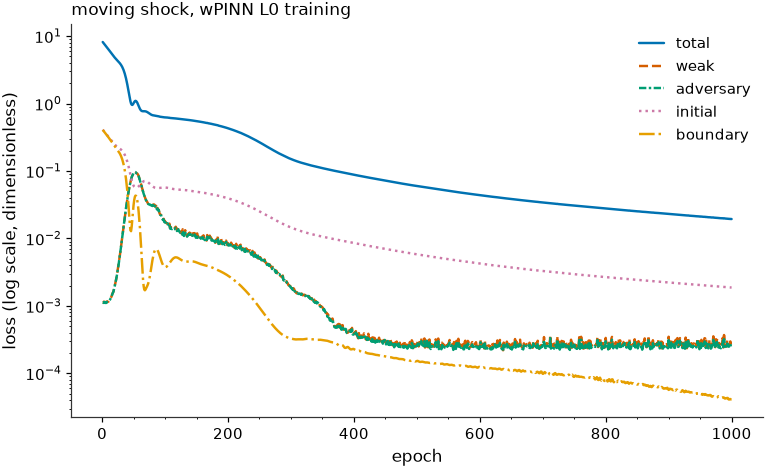

In [15]:
fig, ax = plt.subplots()
epochs = np.arange(1, len(history_L0["total"]) + 1)
ax.semilogy(epochs, history_L0["total"], linestyle="-", label="total")
ax.semilogy(epochs, history_L0["weak"], linestyle="--", label="weak")
ax.semilogy(epochs, history_L0["adversary"], linestyle=(0, (3, 1, 1, 1)), label="adversary")
ax.semilogy(epochs, history_L0["initial"], linestyle=":", label="initial")
ax.semilogy(epochs, history_L0["boundary"], linestyle="-.", label="boundary")
ax.set_xlabel("epoch")
ax.set_ylabel("loss (log scale, dimensionless)")
ax.set_title("moving shock, wPINN L0 training")
ax.legend()
plt.show()

#### Figura 2: solución de L0 en t = T

**Figura 2.** Solución en $t = T = 0.5$: exacta (izquierda), red (centro) y error absoluto
(derecha). Las dos primeras comparten escala de color $[0, 1]$. El choque exacto está en
$x = 0.25$; la línea punteada blanca lo marca sobre la red. El error debe concentrarse en una
franja delgada alrededor de esa línea.

relative L1 error at t = T: 0.0506


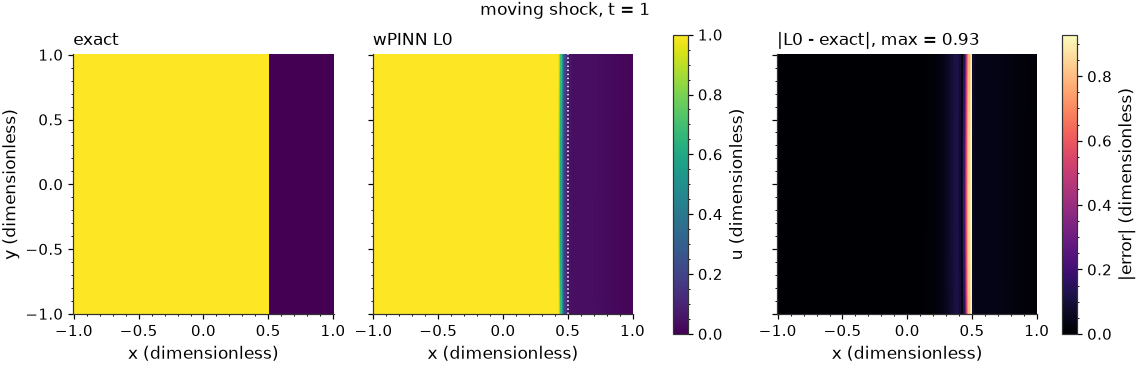

In [16]:
u_predicted = evaluate(u_network_L0, X, Y, np.full_like(X, T))
u_exact = exact_solution(X, T)
error = np.abs(u_predicted - u_exact)

# Error relativo L1 (el natural para leyes de conservación).
relative_l1_error = error.sum() / np.abs(u_exact).sum()
print(f"relative L1 error at t = T: {relative_l1_error:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4), sharey=True)
mesh = axes[0].pcolormesh(x_axis, y_axis, u_exact, cmap="viridis", vmin=0, vmax=1, shading="auto")
axes[0].set_title("exact")
mesh = axes[1].pcolormesh(x_axis, y_axis, u_predicted, cmap="viridis", vmin=0, vmax=1, shading="auto")
axes[1].axvline(shock_speed * T, color="white", linestyle=":", linewidth=1.0)
axes[1].set_title("wPINN L0")
fig.colorbar(mesh, ax=axes[:2], label="u (dimensionless)")
error_mesh = axes[2].pcolormesh(x_axis, y_axis, error, cmap="magma", vmin=0, shading="auto")
axes[2].set_title(f"|L0 - exact|, max = {error.max():.2g}")
fig.colorbar(error_mesh, ax=axes[2], label="|error| (dimensionless)")
for ax in axes:
    ax.set_xlabel("x (dimensionless)")
    ax.set_aspect("equal")
axes[0].set_ylabel("y (dimensionless)")
fig.suptitle(f"moving shock, t = {T}")
plt.show()

#### Figura 3: cortes de L0 en y = 0

**Figura 3.** Corte en $y = 0$ en tres tiempos. Como el dato no depende de $y$, este corte es
toda la historia: la exacta (negro) es un escalón que se mueve de $x = 0$ a $x = 0.25$. Se ve
cuánto suaviza la red el salto y si llega a la posición correcta.

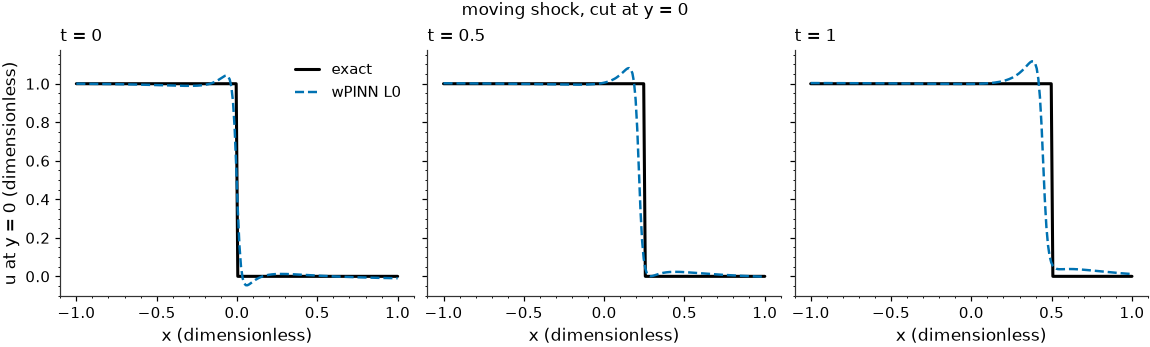

In [17]:
times = [0.0, T / 2, T]
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.2), sharey=True)

for ax, time_value in zip(axes, times):
    u_cut = evaluate(u_network_L0, x_axis, np.zeros_like(x_axis), np.full_like(x_axis, time_value))
    ax.plot(x_axis, exact_solution(x_axis, time_value), color="black", linewidth=2.0, label="exact")
    ax.plot(x_axis, u_cut, linestyle="--", label="wPINN L0")
    ax.set_title(f"t = {time_value:.3g}")
    ax.set_xlabel("x (dimensionless)")

axes[0].set_ylabel("u at y = 0 (dimensionless)")
axes[0].legend()
fig.suptitle("moving shock, cut at y = 0")
plt.show()

### 2.3 Comparación L0 vs L1 vs L2

#### Figura 4: corte de L0, L1 y L2 en t = T

**Figura 4.** Corte en $y = 0$ y $t = T$ de las tres redes contra la exacta (negro), que salta de
1 a 0 en $x = 0.25$. Aquí se ve qué pérdida pone el choque en el lugar correcto y cuál lo suaviza
más.

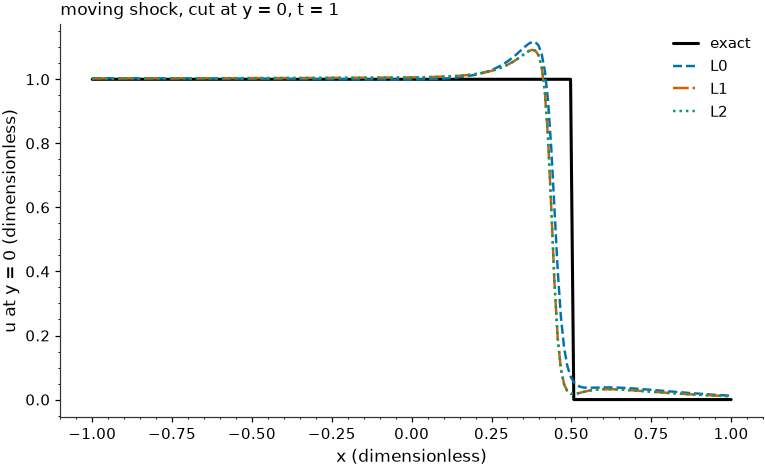

In [18]:
networks = {"L0": u_network_L0, "L1": u_network_L1, "L2": u_network_L2}
# Estilos de línea distintos y no sólo colores: se lee también en blanco y negro.
line_styles = {"L0": "--", "L1": "-.", "L2": ":"}

fig, ax = plt.subplots()
ax.plot(x_axis, exact_solution(x_axis, T), color="black", linewidth=2.0, label="exact")
for name, network in networks.items():
    u_cut = evaluate(network, x_axis, np.zeros_like(x_axis), np.full_like(x_axis, T))
    ax.plot(x_axis, u_cut, linestyle=line_styles[name], label=name)
ax.set_xlabel("x (dimensionless)")
ax.set_ylabel("u at y = 0 (dimensionless)")
ax.set_title(f"moving shock, cut at y = 0, t = {T}")
ax.legend()
plt.show()

#### Figura 5: mapas y errores de L0, L1 y L2

**Figura 5.** Arriba: solución de cada pérdida en $t = T$, con la misma escala $[0, 1]$; la línea
punteada blanca es el choque exacto en $x = 0.25$. Abajo: error absoluto, con **la misma escala
para las tres**, así que un panel más oscuro es de verdad un error menor. La tabla impresa da los
errores relativos $L^1$ y $L^2$.

loss     rel. L1   rel. L2
L0        0.0506    0.1522
L1        0.0560    0.1782
L2        0.0560    0.1783


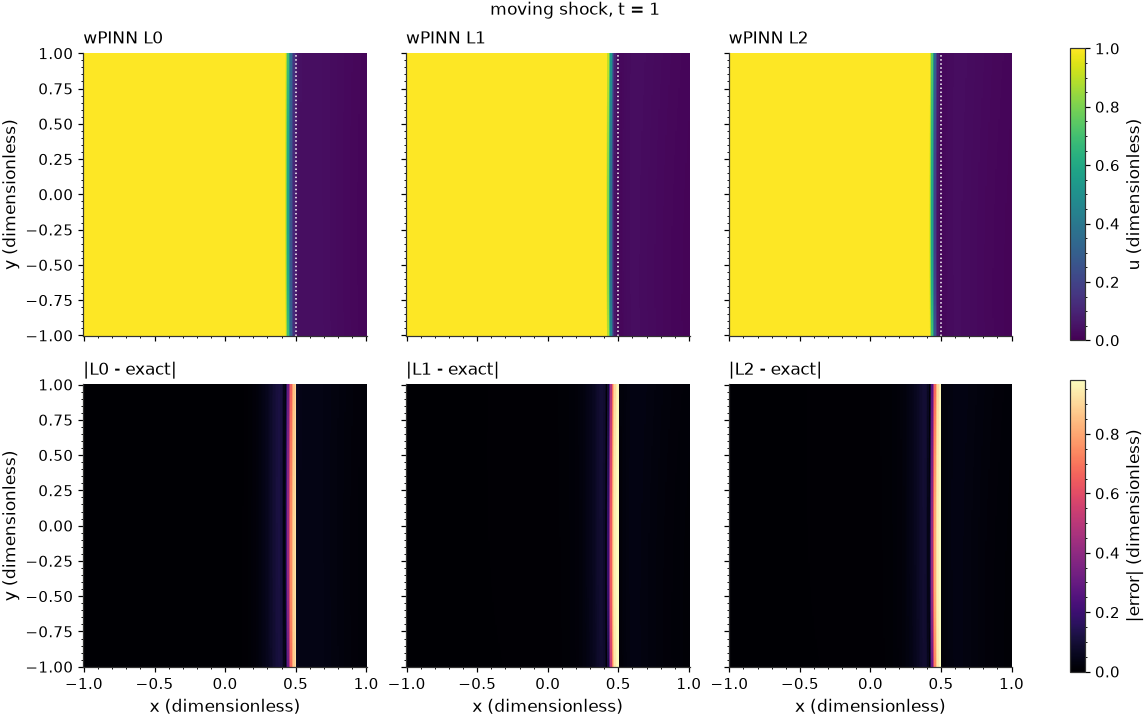

In [19]:
u_exact = exact_solution(X, T)
predictions = {name: evaluate(network, X, Y, np.full_like(X, T)) for name, network in networks.items()}
errors = {name: np.abs(u_predicted - u_exact) for name, u_predicted in predictions.items()}

# Tabla de errores relativos en t = T.
print(f"{'loss':6s} {'rel. L1':>9s} {'rel. L2':>9s}")
for name, error in errors.items():
    relative_l1 = error.sum() / np.abs(u_exact).sum()
    relative_l2 = np.sqrt((error**2).sum()) / np.sqrt((u_exact**2).sum())
    print(f"{name:6s} {relative_l1:9.4f} {relative_l2:9.4f}")

# Misma escala de error para las tres: si cada panel tuviera la suya, la comparación mentiría.
error_max = max(error.max() for error in errors.values())

fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.6), sharex=True, sharey=True)
for column, name in enumerate(networks):
    mesh = axes[0, column].pcolormesh(x_axis, y_axis, predictions[name], cmap="viridis", vmin=0, vmax=1, shading="auto")
    axes[0, column].axvline(shock_speed * T, color="white", linestyle=":", linewidth=1.0)
    axes[0, column].set_title(f"wPINN {name}")
    error_mesh = axes[1, column].pcolormesh(x_axis, y_axis, errors[name], cmap="magma", vmin=0, vmax=error_max, shading="auto")
    axes[1, column].set_title(f"|{name} - exact|")

fig.colorbar(mesh, ax=axes[0, :], label="u (dimensionless)")
fig.colorbar(error_mesh, ax=axes[1, :], label="|error| (dimensionless)")
for ax in axes.flat:
    ax.set_aspect("equal")
for ax in axes[1, :]:
    ax.set_xlabel("x (dimensionless)")
for ax in axes[:, 0]:
    ax.set_ylabel("y (dimensionless)")
fig.suptitle(f"moving shock, t = {T}")
plt.show()

#### Figura 6: ajuste de los datos

**Figura 6.** Ajuste de los datos (pérdida inicial + frontera) por época para cada pérdida, en
escala logarítmica. No se compara el residual débil porque L0, L1 y L2 miden cosas distintas y
sus valores no son comparables; los términos de datos sí son idénticos en las tres. Si una curva
queda arriba, esa pérdida está peleando contra el dato.

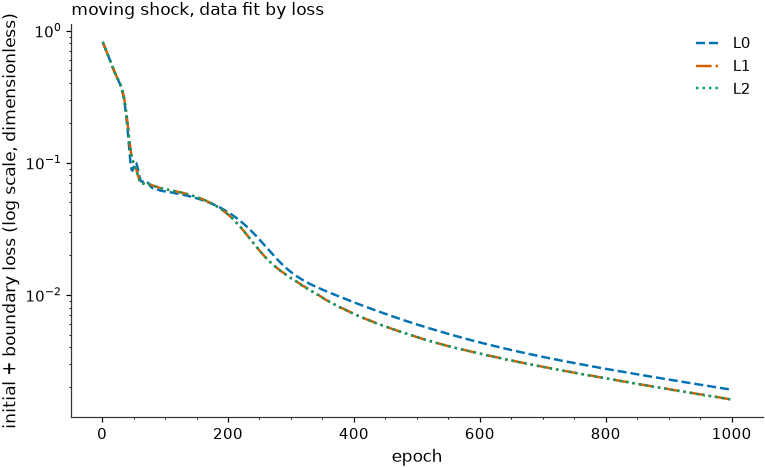

In [20]:
histories = {"L0": history_L0, "L1": history_L1, "L2": history_L2}

fig, ax = plt.subplots()
for name, history in histories.items():
    # Inicial + frontera: la única parte de la pérdida que significa lo mismo en las tres.
    data_loss = np.array(history["initial"]) + np.array(history["boundary"])
    epochs = np.arange(1, len(data_loss) + 1)
    ax.semilogy(epochs, data_loss, linestyle=line_styles[name], label=name)
ax.set_xlabel("epoch")
ax.set_ylabel("initial + boundary loss (log scale, dimensionless)")
ax.set_title("moving shock, data fit by loss")
ax.legend()
plt.show()

## 3. Experimento 2: punto de silla del min-max

La wPINN resuelve $\min_\theta \max_\eta F(\theta, \eta)$. Si el entrenamiento llegó a un
equilibrio, alrededor del punto final $(\theta^*, \eta^*)$ la función $F$ debe ser **mínima en la
dirección de $\theta$** (la red $u$) y **máxima en la dirección de $\eta$** (la red $\varphi$):
una silla de montar.

$\theta$ tiene unos 2200 pesos y $\eta$ unos 380, así que se proyecta en un plano:

- $\alpha$ (pesos de $u$): la recta del entrenamiento, $\theta(\alpha) = \theta_0 + \alpha\,(\theta^* - \theta_0)$.
  $\alpha = 0$ es la red inicial y $\alpha = 1$ la final.
- $\beta$ (pesos de $\varphi$): una dirección aleatoria $d$ con la misma norma que los pesos, capa
  por capa: $\eta(\beta) = \eta^* + \beta\, d$. Es aleatoria a propósito: la dirección del ascenso
  haría que todo pareciera una silla.

$F$ es lo que maximiza la adversaria más los datos:
$F = \max_c R|R| / \|\nabla\varphi\|^2 + \lambda\,(\text{inicial} + \text{frontera})$.

**Lo que mostró la primera versión.** Con $\eta^*$ obtenida de **una sola** adversaria de 200
pasos, el corte en $\alpha$ tenía un mínimo claro en $\alpha = 1$, pero en $\beta$ el punto final
**no era un máximo**: en L0 era incluso un mínimo, y perturbaciones al azar de $\varphi$
encontraban violaciones mayores que la adversaria entrenada. Además, la vista global quedaba
dominada por la red inicial ($F \approx 10$ contra $F^* \approx 0.01$), así que $\beta$ no se veía.

**Lo que hace esta versión:**

1. **$\eta^*$ = la mejor de 10 adversarias** (10 reinicios × 200 pasos). Si con eso $\eta^*$ se
   vuelve un máximo en $\beta$, la silla aparece. Si no, el problema es que la adversaria no
   encuentra el peor $\varphi$.
2. **Vista local fina** alrededor del punto final ($\alpha \in [0.95, 1.05]$, $\beta \in [-0.05, 0.05]$),
   graficando $F - F^*$ con un mapa divergente centrado en 0: **una silla se ve como cuatro cuadrantes**
   rojo/azul alternados; un mínimo se ve todo rojo alrededor del punto y un máximo todo azul.
3. **La parte débil por separado.** $F$ = parte débil + datos, y los datos no dependen de $\varphi$:
   en $\alpha$ dominan los datos y en $\beta$ sólo se mueve la parte débil. Por eso se grafica también
   la parte débil sola, con su propia escala.
4. **Cortes 1D**: $\alpha$ en la vista global con la trayectoria del entrenamiento, y $\beta$ en la
   vista ancha ($[-1, 1]$) comparando la adversaria única (la versión anterior) con la mejor de 10.

**Lo que mostró la segunda versión** (con $\beta \in [-1, 1]$ y paso 0.1): el punto final sí era mínimo
en $\alpha$ y máximo en $\beta$, pero el máximo en $\beta$ ocupaba **un solo punto de la malla**. Ya en
$\beta = \pm 0.1$ (mover un 10 % cada peso de $\varphi$) la adversaria se destruye y $F$ cae a una meseta
que es casi sólo el término de datos. El mapa no mostraba los cuatro cuadrantes porque la malla no
resolvía el pico. Por eso esta versión afina $\beta$ (paso 0.005) y estrecha $\alpha$ (paso 0.005), de
modo que $F$ varíe en las dos direcciones en escalas parecidas.

**Ojo con L1.** Su término extra (tasa de entropía más flujo por el borde) no lleva $\varphi$, pero el residual se divide por
$\|\nabla\varphi\|^2$. Si ese término es positivo para algún $c$, la adversaria puede inflar el
cociente sin límite achicando $\varphi$: el máximo en $\eta$ es infinito y el ascenso diverge
(los pesos terminan en NaN). En el entrenamiento no explota porque la adversaria da sólo 5
pasos, pero con 200 sí. Los reinicios que divergen se descartan y se informa cuántos fueron.

### 3.1 Cálculo de las superficies

In [21]:
def game_objective_parts(u_network, points, level, data_weight=10.0):
    # F(theta, eta) con la red test tal como está ahora, separada en (parte débil, datos).
    # Se separan porque los datos no dependen de phi: en beta sólo se mueve la parte débil.
    u = u_network(points)
    # Sin create_graph: aquí sólo se evalúa, no se entrena.
    u_gradient = torch.autograd.grad(u.sum(), points)[0]
    phi, phi_x, phi_y = test_function(points)
    boundary_flux = boundary_entropy_flux(u_network).detach() if level >= 1 else None
    R, norm = weak_residual(u.detach(), u_gradient, phi.detach(), phi_x.detach(), phi_y.detach(), level,
                            boundary_flux=boundary_flux)
    weak = (R * R.abs() / norm).max()
    with torch.no_grad():
        initial_loss, boundary_loss = data_losses(u_network)
    return weak.item(), (data_weight * (initial_loss + boundary_loss)).item()


def game_objective(u_network, points, level, data_weight=10.0):
    # F = parte débil + datos. Devuelve un número.
    weak, data = game_objective_parts(u_network, points, level, data_weight)
    return weak + data


def random_direction_like(network):
    # Dirección aleatoria con la misma norma que los pesos, capa por capa.
    # Sin esto, una capa de pesos chicos quedaría aplastada por una de pesos grandes.
    pieces = []
    for parameter in network.parameters():
        direction = torch.randn_like(parameter)
        pieces.append((direction / direction.norm() * parameter.norm()).flatten())
    return torch.cat(pieces).detach()


def saddle_landscape(u_network, history, level, alphas_global, alphas_local, betas_local, betas_wide,
                     n_restarts=10, n_adversary_steps=200):
    # Todo lo que piden las figuras 7 a 9, en un diccionario.
    # Los puntos de siempre (uniformes), por si el experimento 5 dejó otros en los globales.
    global interior_points, interior_weights
    interior_points = uniform_interior_points
    interior_weights = torch.ones(n_interior, 1, device=device)
    # Para evaluar F uso 4000 de los puntos interiores y no los 16000, para que sea rápido.
    points = interior_points[:4000].detach().clone().requires_grad_(True)

    # --- 1. eta*: la mejor de n_restarts adversarias ---------------------------
    torch.manual_seed(0)
    restart_values = []
    restart_parameters = []
    for restart in range(n_restarts):
        test_optimizer = reset_test_network()
        adversary_ascent(u_network, test_optimizer, n_adversary_steps, level)
        restart_values.append(game_objective(u_network, points, level))
        restart_parameters.append(parameters_to_vector(test_network.parameters()).detach().clone())
    restart_values = np.array(restart_values)
    # Un reinicio puede diverger (F = inf o nan): se descarta. Si divergen todos, no hay paisaje.
    finite = np.isfinite(restart_values)
    if not finite.any():
        return {"restart_values": restart_values, "final_value": np.nan}
    eta_best = restart_parameters[int(np.argmax(np.where(finite, restart_values, -np.inf)))]
    # Una sola adversaria (lo que hacía la versión anterior): el primer reinicio que no divergió.
    eta_single = restart_parameters[int(np.argmax(finite))]

    # Dirección beta escalada con las normas de eta_best.
    vector_to_parameters(eta_best, test_network.parameters())
    beta_direction = random_direction_like(test_network)

    # --- 2. dirección alpha: de la u inicial a la u final ---------------------
    theta_initial = history["u_parameters"][0].to(device)
    theta_final = parameters_to_vector(u_network.parameters()).detach().clone()
    alpha_direction = theta_final - theta_initial
    # Copia de la red para mover sus pesos sin dañar la red entrenada.
    probe_network = copy.deepcopy(u_network)

    def objective_parts_at(alpha, eta):
        # (parte débil, datos) con u en theta(alpha) y la red test en eta.
        vector_to_parameters(eta, test_network.parameters())
        vector_to_parameters(theta_initial + alpha * alpha_direction, probe_network.parameters())
        return game_objective_parts(probe_network, points, level)

    def objective_at(alpha, eta):
        # F = parte débil + datos en ese punto.
        return sum(objective_parts_at(alpha, eta))

    # --- 3. superficie local fina alrededor del punto final --------------------
    # Forma (n_beta, n_alpha), la de meshgrid. Se guardan las dos partes: F total y sólo la débil.
    local_weak_surface = np.zeros((len(betas_local), len(alphas_local)))
    local_data_surface = np.zeros_like(local_weak_surface)
    for i, beta in enumerate(betas_local):
        for j, alpha in enumerate(alphas_local):
            local_weak_surface[i, j], local_data_surface[i, j] = objective_parts_at(alpha, eta_best + beta * beta_direction)

    # --- 4. cortes 1D ---------------------------------------------------------
    alpha_cut = np.array([objective_at(alpha, eta_best) for alpha in alphas_global])
    # Cortes en beta en la vista ancha: ahí se ve el pico y la meseta de datos.
    beta_cut_best = np.array([objective_at(1.0, eta_best + beta * beta_direction) for beta in betas_wide])
    beta_cut_single = np.array([objective_at(1.0, eta_single + beta * beta_direction) for beta in betas_wide])

    # --- 5. la trayectoria del entrenamiento, vista desde eta_best -------------
    vector_to_parameters(eta_best, test_network.parameters())
    trajectory_alpha = []
    trajectory_value = []
    for theta in history["u_parameters"]:
        theta = theta.to(device)
        # Proyección de theta sobre la recta del entrenamiento.
        alpha = torch.dot(theta - theta_initial, alpha_direction) / torch.dot(alpha_direction, alpha_direction)
        vector_to_parameters(theta, probe_network.parameters())
        trajectory_alpha.append(alpha.item())
        trajectory_value.append(game_objective(probe_network, points, level))

    final_weak, final_data = objective_parts_at(1.0, eta_best)
    return {
        "restart_values": restart_values,
        "final_value": final_weak + final_data,           # F* = F(theta*, eta*)
        "final_weak_value": final_weak,                    # parte débil de F*
        "local_surface": local_weak_surface + local_data_surface,
        "local_weak_surface": local_weak_surface,
        "alpha_cut": alpha_cut,
        "beta_cut_best": beta_cut_best,
        "beta_cut_single": beta_cut_single,
        "trajectory_alpha": np.array(trajectory_alpha),
        "trajectory_value": np.array(trajectory_value),
    }

In [22]:
alphas_global = np.linspace(-0.25, 1.25, 31)   # vista global: de antes de la red inicial a después de la final
# Vista local fina: paso 0.005 en las dos direcciones. Con beta de paso 0.1 el máximo en beta ocupaba
# un solo punto (la adversaria se destruye al mover un 10 % sus pesos). La ventana en alpha se
# estrecha a [0.95, 1.05] para que F varíe en alpha en la misma escala que en beta.
alphas_local = np.linspace(0.95, 1.05, 21)
betas_local = np.linspace(-0.05, 0.05, 21)      # incluye beta = 0 (eta*)
# Vista ancha en beta, sólo para los cortes 1D: muestra el pico y la meseta de datos.
betas_wide = np.linspace(-1.0, 1.0, 21)

landscapes = {}
for name, network, history, level in [("L0", u_network_L0, history_L0, 0),
                                      ("L1", u_network_L1, history_L1, 1),
                                      ("L2", u_network_L2, history_L2, 2)]:
    start = time.time()
    landscapes[name] = saddle_landscape(network, history, level, alphas_global, alphas_local,
                                        betas_local, betas_wide)
    restart_values = landscapes[name]["restart_values"]
    finite_values = restart_values[np.isfinite(restart_values)]
    n_diverged = len(restart_values) - len(finite_values)
    if len(finite_values) == 0:
        print(f"{name}: all {len(restart_values)} adversary restarts diverged  [{time.time() - start:.0f} s]")
        continue
    # Si los reinicios dan valores muy distintos, una sola adversaria no basta para encontrar el peor phi.
    print(f"{name}: F with each adversary restart  min {finite_values.min():.4f}  "
          f"median {np.median(finite_values):.4f}  max {finite_values.max():.4f}  "
          f"diverged {n_diverged}/{len(restart_values)}  [{time.time() - start:.0f} s]")

L0: F with each adversary restart  min 0.0205  median 0.0285  max 0.0370  diverged 0/10  [8 s]
L1: F with each adversary restart  min 0.0178  median 0.0269  max 0.0301  diverged 6/10  [9 s]
L2: F with each adversary restart  min 0.0209  median 0.0267  max 0.0372  diverged 6/10  [9 s]


### 3.2 Figuras

#### Figura 7: superficie local del min-max

**Figura 7.** $F - F^*$ alrededor del punto final, con $\alpha \in [0.95, 1.05]$ (pesos de $u$) y
$\beta \in [-0.05, 0.05]$ (pesos de $\varphi$, $\eta^*$ = la mejor de 10 adversarias). Se resta $F^*$
para que el punto final quede en 0: rojo es más alto y azul más bajo que el punto final. En una
silla la superficie **sube** en $\alpha$ y **baja** en $\beta$. La línea negra es el tramo final
de la trayectoria del entrenamiento **proyectada sobre la superficie** (su $\alpha$ en la recta
del entrenamiento, $\beta = 0$); su valor real de $F$ está en la figura 9. La escala es propia de cada panel. Un panel vacío significa que todas las adversarias de esa pérdida divergieron.


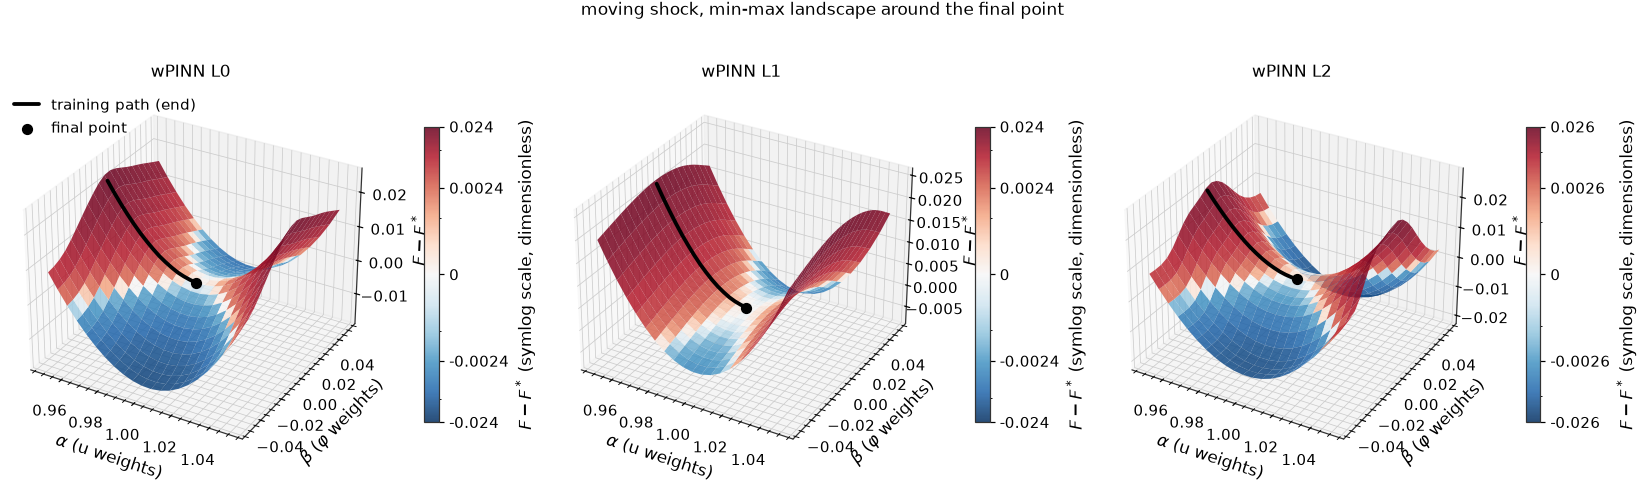

In [23]:
from matplotlib.colors import SymLogNorm   # color lineal cerca de 0 y logarítmico lejos

alpha_grid, beta_grid = np.meshgrid(alphas_local, betas_local)
center_row = np.argmin(np.abs(betas_local))   # fila de beta = 0


def symmetric_log_norm(relative):
    # Límites simétricos (el blanco queda en F = F*) y zona lineal de un 5 % del máximo:
    # así se ven a la vez las variaciones chicas en beta y las grandes en alpha.
    limit = np.abs(relative).max()
    return SymLogNorm(linthresh=0.05 * limit, vmin=-limit, vmax=limit)


def add_symlog_colorbar(fig, mappable, ax, relative, label=r"$F - F^*$ (symlog scale, dimensionless)", **kwargs):
    # Colorbar con 5 marcas legibles; las automáticas de symlog se amontonan cerca de 0.
    limit = np.abs(relative).max()
    colorbar = fig.colorbar(mappable, ax=ax, label=label, **kwargs)
    colorbar.set_ticks([-limit, -0.1 * limit, 0.0, 0.1 * limit, limit])
    colorbar.set_ticklabels([f"{value:.2g}" for value in [-limit, -0.1 * limit, 0.0, 0.1 * limit, limit]])


fig = plt.figure(figsize=(15.0, 4.8))
for k, (name, landscape) in enumerate(landscapes.items()):
    # computed_zorder=False: respeta el zorder, así la trayectoria se dibuja encima de la superficie.
    ax = fig.add_subplot(1, 3, k + 1, projection="3d", computed_zorder=False)
    ax.set_title(f"wPINN {name}")
    if not np.isfinite(landscape["final_value"]):
        ax.set_axis_off()
        ax.text2D(0.5, 0.5, "all adversaries diverged", transform=ax.transAxes, ha="center")
        continue
    relative = landscape["local_surface"] - landscape["final_value"]
    surf = ax.plot_surface(alpha_grid, beta_grid, relative, cmap="RdBu_r", norm=symmetric_log_norm(relative),
                           linewidth=0, alpha=0.85, zorder=1)
    # Tramo final de la trayectoria, proyectado sobre la superficie: para cada alpha de la
    # trayectoria se toma la altura de la superficie en beta = 0. Así la línea queda "montada".
    inside = landscape["trajectory_alpha"] >= alphas_local[0]
    path_alpha = landscape["trajectory_alpha"][inside]
    path_height = np.interp(path_alpha, alphas_local, relative[center_row])
    ax.plot(path_alpha, np.zeros_like(path_alpha), path_height,
            color="black", linewidth=2.5, label="training path (end)", zorder=10)
    ax.scatter([1.0], [0.0], [0.0], color="black", s=40, label="final point", zorder=11)
    ax.set_xlabel(r"$\alpha$ (u weights)")
    ax.set_ylabel(r"$\beta$ ($\varphi$ weights)")
    ax.set_zlabel(r"$F - F^*$")
    add_symlog_colorbar(fig, surf, ax, relative, shrink=0.6, pad=0.12)
fig.axes[0].legend(loc="upper left")
fig.suptitle("moving shock, min-max landscape around the final point")
plt.show()

#### Figura 8: mapa local del min-max

**Figura 8.** Arriba, el mismo $F - F^*$ de la figura 7 visto desde arriba. Abajo, **sólo la parte
débil**, $W - W^*$ con $W = \max_c R|R| / \|\nabla\varphi\|^2$: sin el término de datos, que no depende de
$\varphi$ y domina la curvatura en $\alpha$. Cada fila tiene su propia escala de color. El punto negro es el
punto final y la línea negra marca el nivel del punto final. **Cómo leerlo:** una silla se ve como cuatro
cuadrantes alternados (rojo a izquierda y derecha, azul arriba y abajo) y la línea de nivel forma una **X**
que cruza el punto final; un mínimo se ve todo rojo alrededor y un máximo todo azul. La escala es
**simétrica-logarítmica** (lineal cerca de 0 y logarítmica lejos). Si la fila de abajo no muestra un mínimo
en $\alpha$, la parte débil sola no fija la red $u$: el mínimo en $\alpha$ lo pone el término de datos.

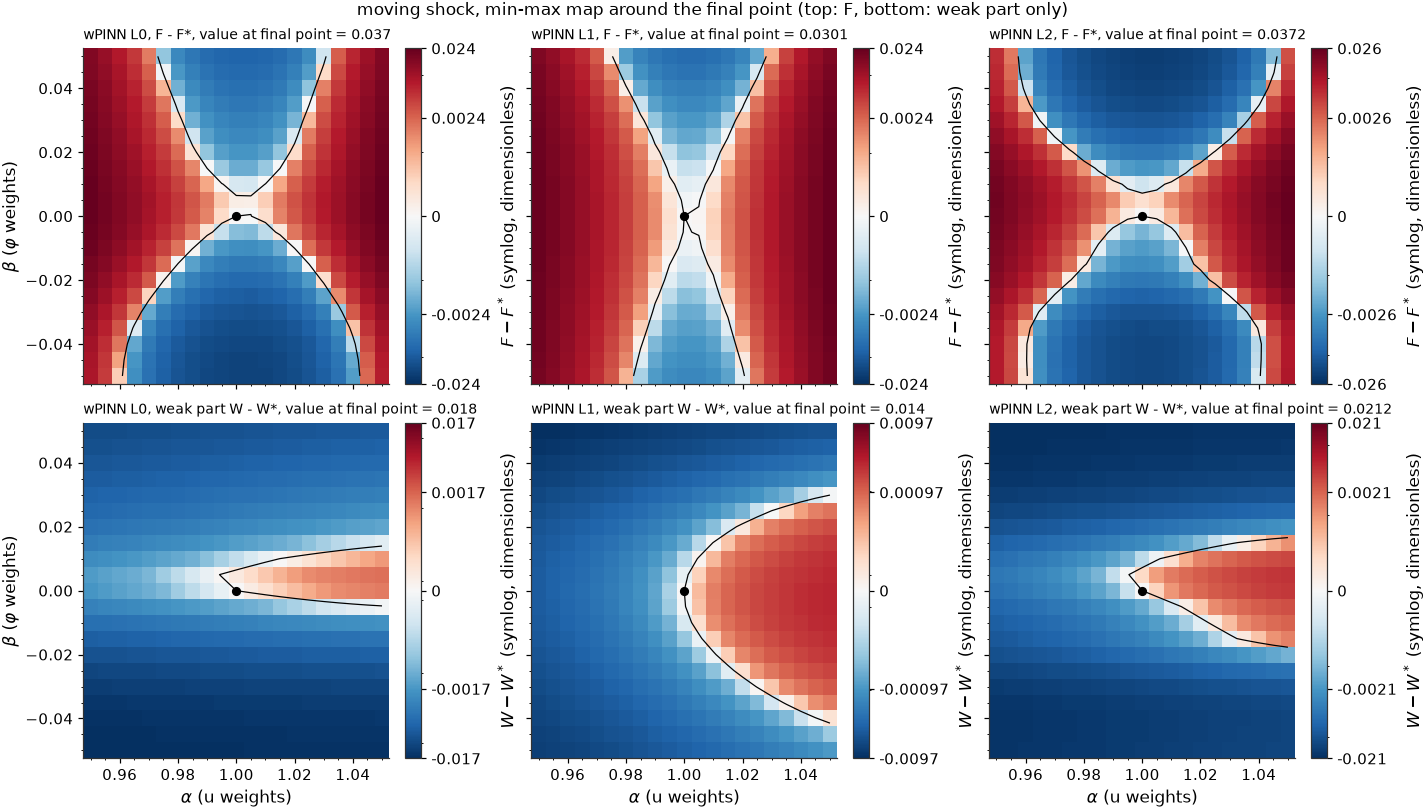

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(13.0, 7.4), layout="constrained", sharex=True, sharey=True)
# Fila de arriba: F total. Fila de abajo: sólo la parte débil (cada una referida a su valor en el punto final).
rows = [("F - F*", "local_surface", "final_value"),
        ("weak part W - W*", "local_weak_surface", "final_weak_value")]
for row, (row_label, surface_key, final_key) in enumerate(rows):
    for column, (name, landscape) in enumerate(landscapes.items()):
        ax = axes[row, column]
        if not np.isfinite(landscape["final_value"]):
            ax.set_title(f"wPINN {name}")
            ax.set_axis_off()
            ax.text(0.5, 0.5, "all adversaries diverged", transform=ax.transAxes, ha="center")
            continue
        relative = landscape[surface_key] - landscape[final_key]
        mesh = ax.pcolormesh(alphas_local, betas_local, relative, cmap="RdBu_r",
                             norm=symmetric_log_norm(relative), shading="auto")
        # Curva de nivel del punto final: en una silla forma una X que lo cruza.
        ax.contour(alphas_local, betas_local, relative, levels=[0.0], colors="black", linewidths=0.8)
        ax.plot(1.0, 0.0, marker="o", color="black")
        ax.set_title(f"wPINN {name}, {row_label}, value at final point = {landscape[final_key]:.3g}",
                     fontsize="small")
        colorbar_label = (r"$F - F^*$" if row == 0 else r"$W - W^*$") + " (symlog, dimensionless)"
        add_symlog_colorbar(fig, mesh, ax, relative, label=colorbar_label)
for ax in axes[1, :]:
    ax.set_xlabel(r"$\alpha$ (u weights)")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$\beta$ ($\varphi$ weights)")
fig.suptitle("moving shock, min-max map around the final point (top: F, bottom: weak part only)")
plt.show()

#### Figura 9: cortes por el punto final

**Figura 9.** Arriba: $F$ a lo largo de $\alpha$ con $\beta = 0$, en la vista global, con la
trayectoria del entrenamiento en rojo (escala logarítmica si $F > 0$, porque la red inicial
tiene una pérdida órdenes de magnitud mayor). Debería tener su mínimo en $\alpha = 1$. Los
puntos rojos quedan **por debajo** de la curva negra porque el entrenamiento no viaja en línea
recta: la recta $\theta_0 \to \theta^*$ pasa por zonas de pérdida más alta que el camino real.
Abajo: $F$ a lo largo de $\beta \in [-1, 1]$ (vista ancha) con $\alpha = 1$, para la adversaria única
(gris, la versión anterior) y la mejor de 10 (azul). La meseta lejos de $\beta = 0$ es casi sólo el
término de datos: ahí $\varphi$ ya no encuentra violaciones. Para que haya silla, la curva azul debe tener su
**máximo** en $\beta = 0$.

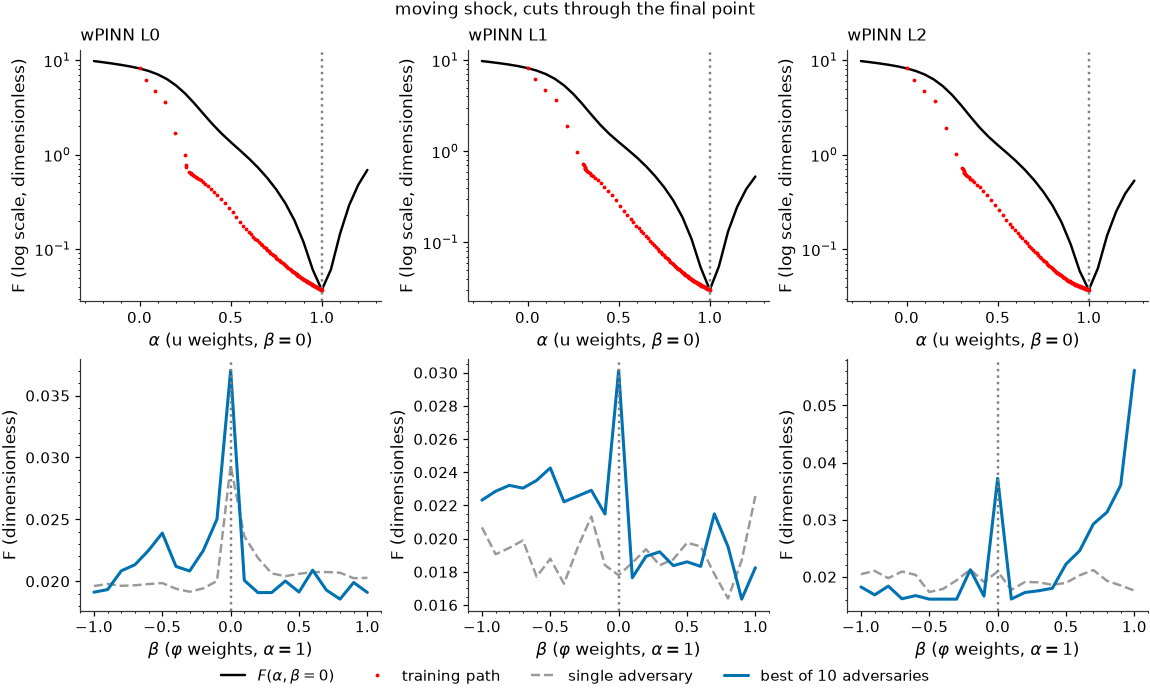

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.4), layout="constrained")
for k, (name, landscape) in enumerate(landscapes.items()):
    top = axes[0, k]
    bottom = axes[1, k]
    top.set_title(f"wPINN {name}")
    top.set_xlabel(r"$\alpha$ (u weights, $\beta = 0$)")
    bottom.set_xlabel(r"$\beta$ ($\varphi$ weights, $\alpha = 1$)")
    if not np.isfinite(landscape["final_value"]):
        for ax in (top, bottom):
            ax.set_axis_off()
            ax.text(0.5, 0.5, "all adversaries diverged", transform=ax.transAxes, ha="center")
        continue

    # Arriba: dirección de u, vista global, con la trayectoria del entrenamiento.
    top.plot(alphas_global, landscape["alpha_cut"], color="black", label=r"$F(\alpha, \beta = 0)$")
    top.plot(landscape["trajectory_alpha"], landscape["trajectory_value"], linestyle="none",
             marker=".", markersize=3, color="red", label="training path")
    top.axvline(1.0, color="gray", linestyle=":")
    if (landscape["alpha_cut"] > 0).all() and (landscape["trajectory_value"] > 0).all():
        top.set_yscale("log")
        top.set_ylabel("F (log scale, dimensionless)")
    else:
        top.set_ylabel("F (dimensionless)")

    # Abajo: dirección de phi en el punto final, adversaria única contra la mejor de 10.
    bottom.plot(betas_wide, landscape["beta_cut_single"], color="0.6", linestyle="--", label="single adversary")
    bottom.plot(betas_wide, landscape["beta_cut_best"], color="C0", linestyle="-", linewidth=2.0, label="best of 10 adversaries")
    bottom.axvline(0.0, color="gray", linestyle=":")
    bottom.set_ylabel("F (dimensionless)")

# Una sola leyenda abajo, fuera de los paneles, para no tapar ninguna curva.
handles, labels = [], []
for ax in axes.flat:
    for handle, label in zip(*ax.get_legend_handles_labels()):
        if label not in labels:
            handles.append(handle)
            labels.append(label)
fig.legend(handles, labels, loc="outside lower center", ncol=4)
fig.suptitle("moving shock, cuts through the final point")
plt.show()

## 4. Experimento 3: casos borde de la función test

El paper le pone tres restricciones a $\varphi$. Aquí se quitan una por una, siempre con L0
para aislar el efecto, y se compara contra la L0 normal.

| Caso | Qué se quita | Para qué estaba | Qué espero |
|---|---|---|---|
| A | positividad (`softplus`) | Kruzhkov es una desigualdad válida sólo para $\varphi \ge 0$ | la adversaria usa $-\varphi$ y la desigualdad se vuelve igualdad: castiga la disipación legítima del choque, que debería salir suavizado o mal ubicado |
| B | ventana $(1-x^2)(1-y^2)$ | anula $\varphi$ en el borde y justifica integrar por partes sin términos de frontera | el residual pierde el término $\int Q\,\varphi\, n$ del borde; la adversaria lo explota y espero errores cerca de $x = \pm 1$ |
| C | normalización $/\|\nabla\varphi\|^2$ | impide ganar sólo escalando $\varphi$ | el objetivo de la adversaria crece sin cota y el residual aplasta a los datos |
| D | positividad y ventana | | $\varphi$ totalmente libre: A y B a la vez |

En el log de cada corrida, mirar sobre todo la columna `adversary`.

### 4.1 Caso A: sin positividad

In [39]:
u_network_no_positive, history_no_positive = train_wpinn(level=0, positive=False, label="A no positive")

A no positive  epoch   100  total 6.262e-01  weak 1.944e-02  adversary 1.946e-02  initial 5.708e-02  boundary 3.596e-03  [2 s]
A no positive  epoch   200  total 4.336e-01  weak 1.296e-02  adversary 1.273e-02  initial 3.960e-02  boundary 2.470e-03  [5 s]
A no positive  epoch   300  total 1.525e-01  weak 7.555e-03  adversary 7.535e-03  initial 1.419e-02  boundary 3.073e-04  [7 s]
A no positive  epoch   400  total 1.088e-01  weak 2.586e-02  adversary 2.572e-02  initial 8.038e-03  boundary 2.571e-04  [9 s]
A no positive  epoch   500  total 7.328e-02  weak 1.831e-02  adversary 1.823e-02  initial 5.335e-03  boundary 1.614e-04  [12 s]
A no positive  epoch   600  total 5.926e-02  weak 2.028e-02  adversary 2.025e-02  initial 3.801e-03  boundary 9.705e-05  [14 s]
A no positive  epoch   700  total 4.969e-02  weak 1.852e-02  adversary 1.842e-02  initial 3.036e-03  boundary 8.096e-05  [16 s]
A no positive  epoch   800  total 5.224e-02  weak 2.340e-02  adversary 2.392e-02  initial 2.810e-03  boundar

### 4.2 Caso B: sin ventana

In [40]:
u_network_no_window, history_no_window = train_wpinn(level=0, window=False, label="B no window")

B no window  epoch   100  total 7.965e+00  weak 3.065e+00  adversary 3.040e+00  initial 2.468e-01  boundary 2.432e-01  [2 s]
B no window  epoch   200  total 7.622e+00  weak 2.710e+00  adversary 2.697e+00  initial 2.507e-01  boundary 2.405e-01  [4 s]
B no window  epoch   300  total 9.444e+00  weak 4.197e+00  adversary 4.182e+00  initial 2.585e-01  boundary 2.662e-01  [7 s]
B no window  epoch   400  total 8.062e+00  weak 2.757e+00  adversary 2.720e+00  initial 2.632e-01  boundary 2.673e-01  [9 s]
B no window  epoch   500  total 7.553e+00  weak 2.426e+00  adversary 2.436e+00  initial 2.581e-01  boundary 2.545e-01  [11 s]
B no window  epoch   600  total 4.602e+00  weak 0.000e+00  adversary 0.000e+00  initial 2.401e-01  boundary 2.201e-01  [13 s]
B no window  epoch   700  total 7.868e+00  weak 4.746e+00  adversary 5.500e+00  initial 1.832e-01  boundary 1.289e-01  [15 s]
B no window  epoch   800  total 7.193e+00  weak 2.493e+00  adversary 2.520e+00  initial 2.442e-01  boundary 2.258e-01  [17

### 4.3 Caso C: sin normalización

Ojo: aquí la pérdida débil no está dividida por $\|\nabla\varphi\|^2$, así que sus valores no se
pueden comparar con los de las otras corridas.

In [41]:
u_network_no_normalize, history_no_normalize = train_wpinn(level=0, normalize=False, label="C no normalize")

C no normalize  epoch   100  total 6.433e-01  weak 6.131e-03  adversary 4.646e-03  initial 5.633e-02  boundary 7.393e-03  [2 s]
C no normalize  epoch   200  total 4.137e-01  weak 7.493e-03  adversary 5.900e-03  initial 3.757e-02  boundary 3.051e-03  [5 s]
C no normalize  epoch   300  total 1.396e-01  weak 1.846e-03  adversary 1.569e-03  initial 1.335e-02  boundary 4.339e-04  [7 s]
C no normalize  epoch   400  total 7.925e-02  weak 8.311e-04  adversary 7.089e-04  initial 7.690e-03  boundary 1.515e-04  [9 s]
C no normalize  epoch   500  total 5.549e-02  weak 1.564e-03  adversary 1.310e-03  initial 5.269e-03  boundary 1.236e-04  [12 s]
C no normalize  epoch   600  total 4.111e-02  weak 1.344e-03  adversary 1.151e-03  initial 3.867e-03  boundary 1.099e-04  [14 s]
C no normalize  epoch   700  total 3.263e-02  weak 1.618e-03  adversary 1.369e-03  initial 3.003e-03  boundary 9.801e-05  [16 s]
C no normalize  epoch   800  total 2.628e-02  weak 1.149e-03  adversary 9.599e-04  initial 2.418e-03 

### 4.4 Caso D: sin positividad y sin ventana

In [42]:
u_network_free, history_free = train_wpinn(level=0, positive=False, window=False, label="D free")

D free  epoch   100  total 6.871e+00  weak 2.240e+00  adversary 7.040e-01  initial 2.431e-01  boundary 2.200e-01  [2 s]
D free  epoch   200  total 4.598e+00  weak 3.226e+00  adversary 3.121e+00  initial 1.094e-01  boundary 2.774e-02  [4 s]
D free  epoch   300  total 2.631e+00  weak 1.665e+00  adversary 1.185e+00  initial 7.739e-02  boundary 1.918e-02  [6 s]
D free  epoch   400  total 2.898e+00  weak 1.954e+00  adversary 1.890e+00  initial 7.368e-02  boundary 2.065e-02  [8 s]
D free  epoch   500  total 2.653e+00  weak 1.915e+00  adversary 1.924e+00  initial 5.937e-02  boundary 1.441e-02  [10 s]
D free  epoch   600  total 2.762e+00  weak 2.127e+00  adversary 1.980e+00  initial 5.181e-02  boundary 1.174e-02  [12 s]
D free  epoch   700  total 2.422e+00  weak 1.721e+00  adversary 1.681e+00  initial 5.178e-02  boundary 1.836e-02  [14 s]
D free  epoch   800  total 2.513e+00  weak 1.999e+00  adversary 1.951e+00  initial 3.908e-02  boundary 1.227e-02  [16 s]
D free  epoch   900  total 2.430e+00

### 4.5 Comparación de los casos borde

#### Figura 10: corte de los casos borde

**Figura 10.** Corte en $y = 0$ y $t = T$ de la L0 normal y los cuatro casos borde, contra la
exacta (negro), que salta de 1 a 0 en $x = 0.25$. Aquí se ve cuál restricción, al quitarla,
mueve o suaviza el choque.

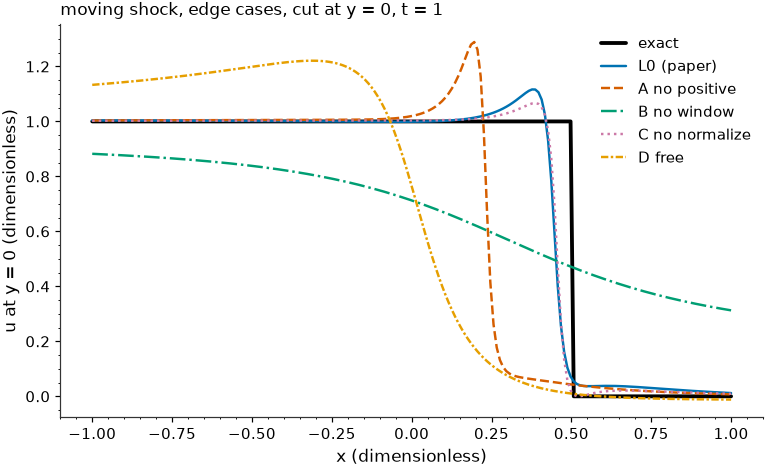

In [43]:
edge_case_networks = {
    "L0 (paper)": u_network_L0,
    "A no positive": u_network_no_positive,
    "B no window": u_network_no_window,
    "C no normalize": u_network_no_normalize,
    "D free": u_network_free,
}
# Cinco estilos de línea distintos: se distinguen también en blanco y negro.
edge_case_line_styles = {
    "L0 (paper)": "-",
    "A no positive": "--",
    "B no window": "-.",
    "C no normalize": ":",
    "D free": (0, (3, 1, 1, 1)),
}

fig, ax = plt.subplots()
ax.plot(x_axis, exact_solution(x_axis, T), color="black", linewidth=2.5, label="exact")
for name, network in edge_case_networks.items():
    u_cut = evaluate(network, x_axis, np.zeros_like(x_axis), np.full_like(x_axis, T))
    ax.plot(x_axis, u_cut, linestyle=edge_case_line_styles[name], label=name)
ax.set_xlabel("x (dimensionless)")
ax.set_ylabel("u at y = 0 (dimensionless)")
ax.set_title(f"moving shock, edge cases, cut at y = 0, t = {T}")
ax.legend()
plt.show()

#### Figura 11: errores de los casos borde

**Figura 11.** Error absoluto en $t = T$ de cada caso, con **la misma escala de color para los
cinco**, así que un panel más oscuro es de verdad un error menor. El caso B debería mostrar
error pegado a los bordes $x = \pm 1$; los casos A y D, alrededor del choque. La tabla impresa
da los errores relativos $L^1$ y $L^2$.

case               rel. L1   rel. L2
L0 (paper)          0.0506    0.1522
A no positive       0.1873    0.3839
B no window         0.3815    0.3591
C no normalize      0.0413    0.1492
D free              0.3793    0.4947


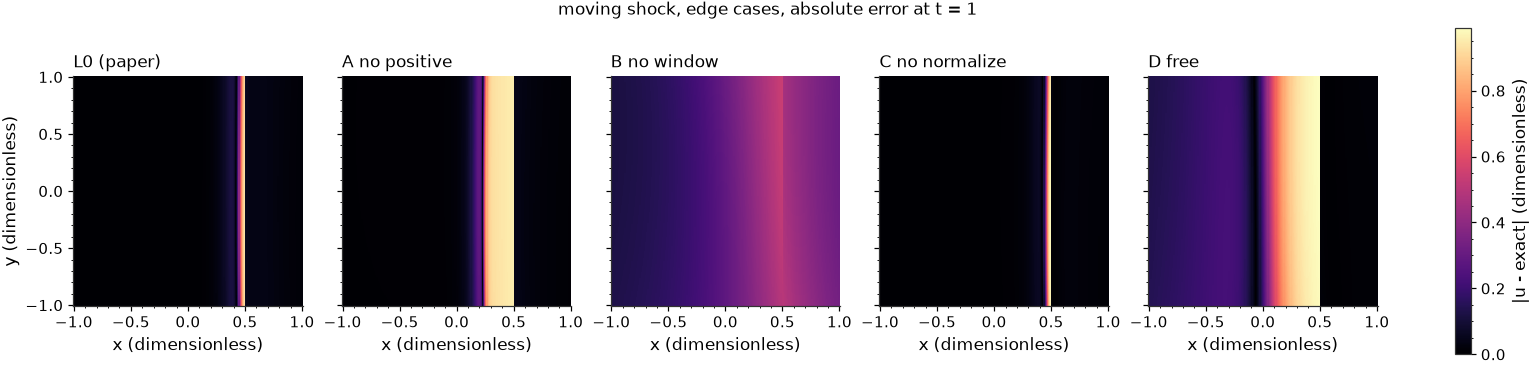

In [44]:
u_exact = exact_solution(X, T)
edge_case_errors = {
    name: np.abs(evaluate(network, X, Y, np.full_like(X, T)) - u_exact)
    for name, network in edge_case_networks.items()
}

# Tabla de errores relativos en t = T.
print(f"{'case':16s} {'rel. L1':>9s} {'rel. L2':>9s}")
for name, error in edge_case_errors.items():
    relative_l1 = error.sum() / np.abs(u_exact).sum()
    relative_l2 = np.sqrt((error**2).sum()) / np.sqrt((u_exact**2).sum())
    print(f"{name:16s} {relative_l1:9.4f} {relative_l2:9.4f}")

# Misma escala para los cinco paneles.
error_max = max(error.max() for error in edge_case_errors.values())

fig, axes = plt.subplots(1, 5, figsize=(14.0, 3.4), sharey=True)
for ax, (name, error) in zip(axes, edge_case_errors.items()):
    error_mesh = ax.pcolormesh(x_axis, y_axis, error, cmap="magma", vmin=0, vmax=error_max, shading="auto")
    ax.set_title(name)
    ax.set_xlabel("x (dimensionless)")
    ax.set_aspect("equal")
axes[0].set_ylabel("y (dimensionless)")
fig.colorbar(error_mesh, ax=axes, label="|u - exact| (dimensionless)")
fig.suptitle(f"moving shock, edge cases, absolute error at t = {T}")
plt.show()

#### Figura 12: objetivo de la adversaria

**Figura 12.** Objetivo que alcanza la adversaria al final del ascenso, por época, en escala
logarítmica. Si una curva sube sin parar, la adversaria encontró una forma de ganar que no tiene
que ver con la física. **El caso C no es comparable en escala** con los demás, porque no está
normalizado; ahí sólo importa su tendencia.

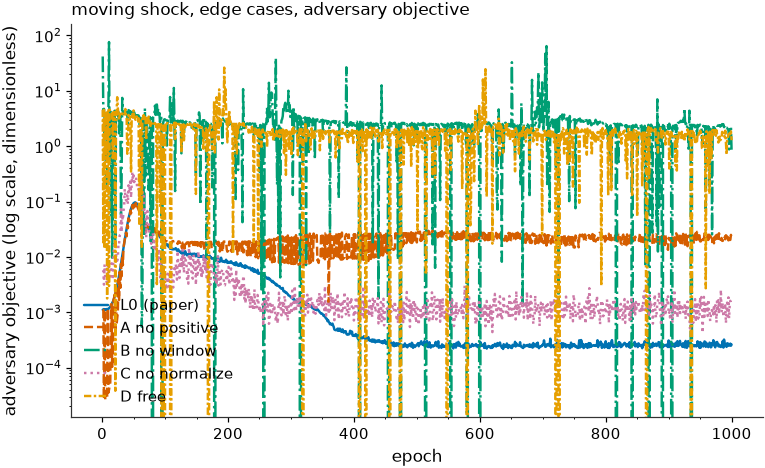

In [45]:
edge_case_histories = {
    "L0 (paper)": history_L0,
    "A no positive": history_no_positive,
    "B no window": history_no_window,
    "C no normalize": history_no_normalize,
    "D free": history_free,
}

fig, ax = plt.subplots()
for name, history in edge_case_histories.items():
    epochs = np.arange(1, len(history["adversary"]) + 1)
    ax.semilogy(epochs, history["adversary"], linestyle=edge_case_line_styles[name], label=name)
ax.set_xlabel("epoch")
ax.set_ylabel("adversary objective (log scale, dimensionless)")
ax.set_title("moving shock, edge cases, adversary objective")
ax.legend()
plt.show()

## 5. Experimento 4: arquitectura de las redes

**Hipótesis:** mientras más minimalista sea la arquitectura, mayor el error; mientras más
compleja, menor.

**Por qué podría no cumplirse.** Espero más bien una curva en U:

- **Red muy chica:** no puede representar un salto brusco y suaviza el choque (subajuste).
- **Red grande con el mismo presupuesto** (1000 épocas, mismo paso): necesita más iteraciones
  para entrenar y no tiene por qué mejorar.
- **Sesgo espectral:** un MLP con tanh aprende primero las frecuencias bajas. El ancho del
  choque lo limita eso más que el tamaño de la red.
- **Equilibrio del min-max:** si $u$ es mucho más poderosa que $\varphi$, la adversaria deja de
  encontrar violaciones y la pérdida débil deja de guiar a $u$. Importa el tamaño **relativo** de
  las dos redes.
- **Norma débil:** la norma $H^{-1}$ es débil. Una pérdida chica no implica un error $L^1$ chico.

| Nombre | $u$ (capas × ancho) | $\varphi$ | Qué pregunta responde |
|---|---|---|---|
| tiny | 2 × 10 | 4 × 10 | extremo minimalista: ¿alcanza para un salto? |
| paper | 6 × 20 | 4 × 10 | línea base |
| deep | 10 × 20 | 4 × 10 | profundidad sin ancho: más composición, más difícil de optimizar |
| wide | 2 × 100 | 4 × 10 | ancho sin profundidad |
| large | 6 × 64 | 4 × 10 | "más es mejor" llevado lejos |
| sine | 6 × 20, `sin` | 4 × 10 | De Ryck usa `sin` en $u$: cambia la forma, no el tamaño |
| weak adversary | 6 × 20 | 1 × 5 | $\varphi$ casi sin capacidad: ¿detecta violaciones? |
| strong adversary | 6 × 20 | 4 × 40 | $\varphi$ más grande que $u$: ¿mejor guía o juego inestable? |

Todas con L0 y **3 semillas** cada una (24 entrenamientos), porque la varianza entre semillas
puede ser tan grande como el efecto de la arquitectura. Es la sección más cara del notebook.

### 5.0 Configuración del experimento

In [46]:
# Arquitecturas: nombre -> argumentos de train_wpinn. Lo que no se escribe toma el valor del paper
# (u: 6 x 20 tanh, phi: 4 x 10).
architectures = {
    "tiny": dict(u_hidden_layers=2, u_width=10),
    "paper": dict(),
    "deep": dict(u_hidden_layers=10, u_width=20),
    "wide": dict(u_hidden_layers=2, u_width=100),
    "large": dict(u_hidden_layers=6, u_width=64),
    "sine": dict(u_activation=Sine),
    "weak adversary": dict(test_hidden_layers=1, test_width=5),
    "strong adversary": dict(test_hidden_layers=4, test_width=40),
}
seeds = [0, 1, 2]
architecture_runs = {}   # nombre -> lista de (red, historia), una por semilla


def run_architecture(name):
    # Entrena la arquitectura con las 3 semillas y guarda los resultados.
    architecture_runs[name] = []
    for seed in seeds:
        network, history = train_wpinn(level=0, seed=seed, label=f"{name}, seed {seed}", **architectures[name])
        architecture_runs[name].append((network, history))


def relative_errors(network):
    # Errores relativos L1 y L2 en t = T sobre la malla de las figuras.
    u_exact = exact_solution(X, T)
    error = np.abs(evaluate(network, X, Y, np.full_like(X, T)) - u_exact)
    relative_l1 = error.sum() / np.abs(u_exact).sum()
    relative_l2 = np.sqrt((error**2).sum()) / np.sqrt((u_exact**2).sum())
    return relative_l1, relative_l2

### 5.1 tiny

El extremo minimalista: unos 160 parámetros. Si la hipótesis es cierta, aquí está el peor error.

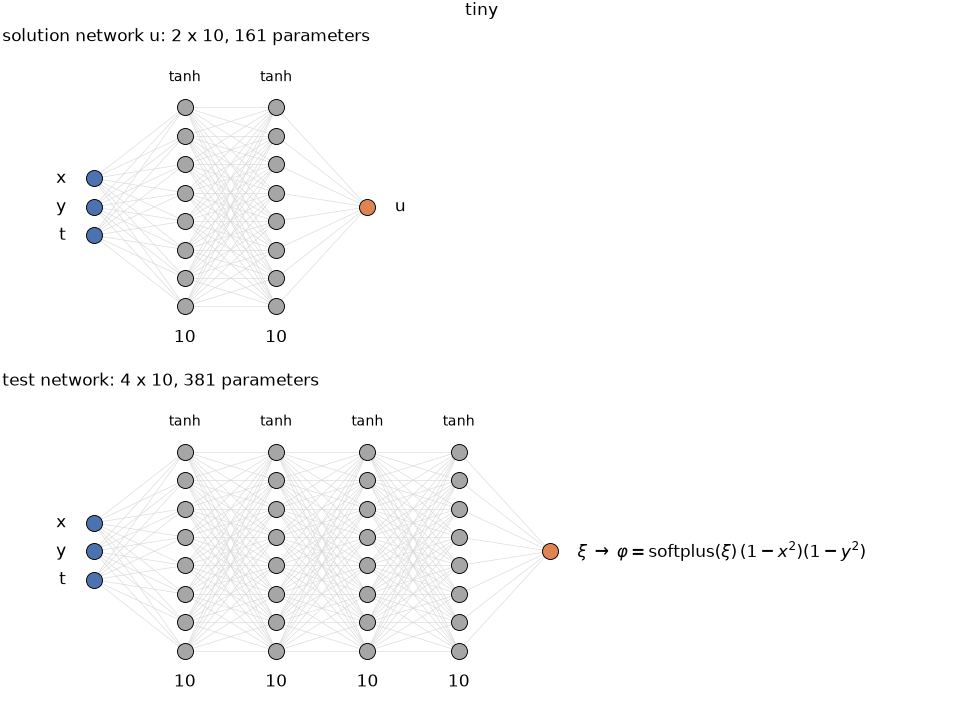

In [47]:
draw_architecture("tiny", **architectures["tiny"])

In [48]:
run_architecture("tiny")

tiny, seed 0  epoch   100  total 1.636e+00  weak 1.207e-03  adversary 1.062e-03  initial 1.233e-01  boundary 4.020e-02  [2 s]
tiny, seed 0  epoch   200  total 7.493e-01  weak 2.717e-02  adversary 2.632e-02  initial 6.598e-02  boundary 6.240e-03  [4 s]
tiny, seed 0  epoch   300  total 7.373e-01  weak 3.380e-02  adversary 3.299e-02  initial 6.500e-02  boundary 5.345e-03  [7 s]
tiny, seed 0  epoch   400  total 7.256e-01  weak 3.540e-02  adversary 3.450e-02  initial 6.384e-02  boundary 5.179e-03  [9 s]
tiny, seed 0  epoch   500  total 7.175e-01  weak 4.079e-02  adversary 3.915e-02  initial 6.254e-02  boundary 5.136e-03  [11 s]
tiny, seed 0  epoch   600  total 6.998e-01  weak 3.741e-02  adversary 3.653e-02  initial 6.111e-02  boundary 5.125e-03  [13 s]
tiny, seed 0  epoch   700  total 6.841e-01  weak 3.793e-02  adversary 3.700e-02  initial 5.952e-02  boundary 5.102e-03  [15 s]
tiny, seed 0  epoch   800  total 6.675e-01  weak 4.096e-02  adversary 3.932e-02  initial 5.767e-02  boundary 4.980e

### 5.2 paper

La línea base: la arquitectura del paper, con las mismas 3 semillas que las demás.

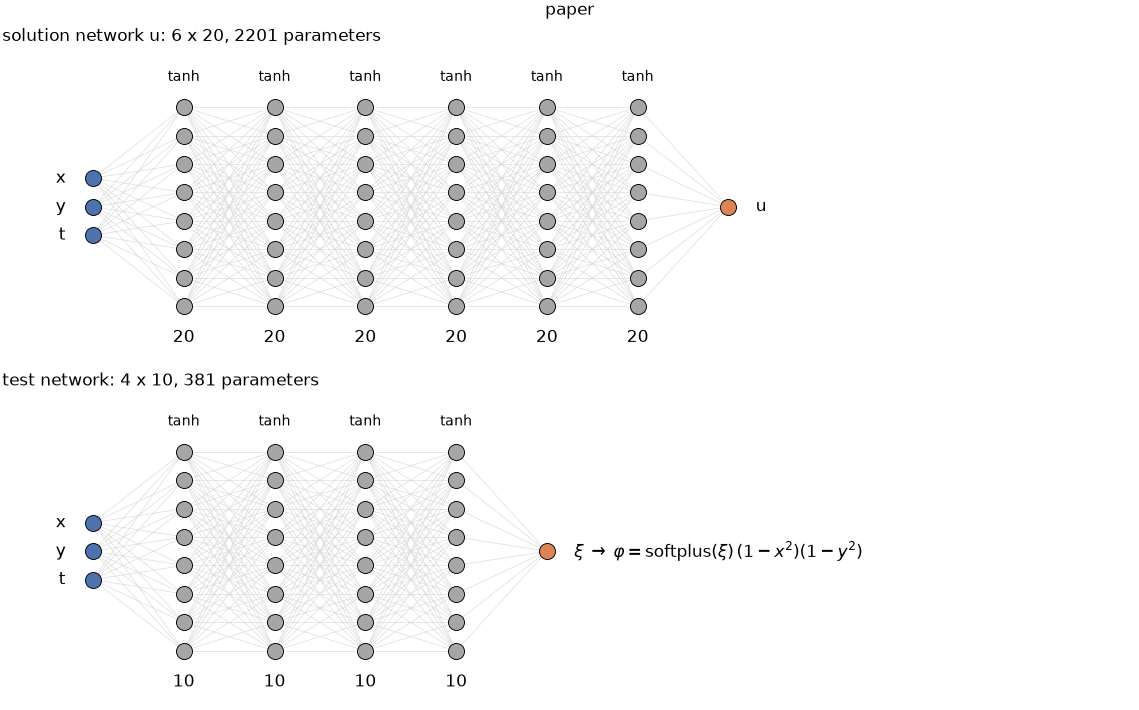

In [49]:
draw_architecture("paper", **architectures["paper"])

In [50]:
run_architecture("paper")

paper, seed 0  epoch   100  total 6.244e-01  weak 1.784e-02  adversary 1.736e-02  initial 5.690e-02  boundary 3.755e-03  [2 s]
paper, seed 0  epoch   200  total 4.305e-01  weak 8.537e-03  adversary 8.191e-03  initial 3.939e-02  boundary 2.807e-03  [5 s]
paper, seed 0  epoch   300  total 1.505e-01  weak 1.876e-03  adversary 1.853e-03  initial 1.454e-02  boundary 3.273e-04  [7 s]
paper, seed 0  epoch   400  total 8.808e-02  weak 3.967e-04  adversary 3.839e-04  initial 8.540e-03  boundary 2.286e-04  [10 s]
paper, seed 0  epoch   500  total 5.991e-02  weak 2.754e-04  adversary 2.596e-04  initial 5.811e-03  boundary 1.526e-04  [12 s]
paper, seed 0  epoch   600  total 4.385e-02  weak 2.567e-04  adversary 2.451e-04  initial 4.236e-03  boundary 1.237e-04  [15 s]
paper, seed 0  epoch   700  total 3.418e-02  weak 2.819e-04  adversary 2.622e-04  initial 3.291e-03  boundary 9.828e-05  [17 s]
paper, seed 0  epoch   800  total 2.785e-02  weak 3.350e-04  adversary 2.988e-04  initial 2.667e-03  bounda

### 5.3 deep

Misma anchura que el paper pero 10 capas: más composición de funciones, pero el gradiente tiene que atravesar más capas.

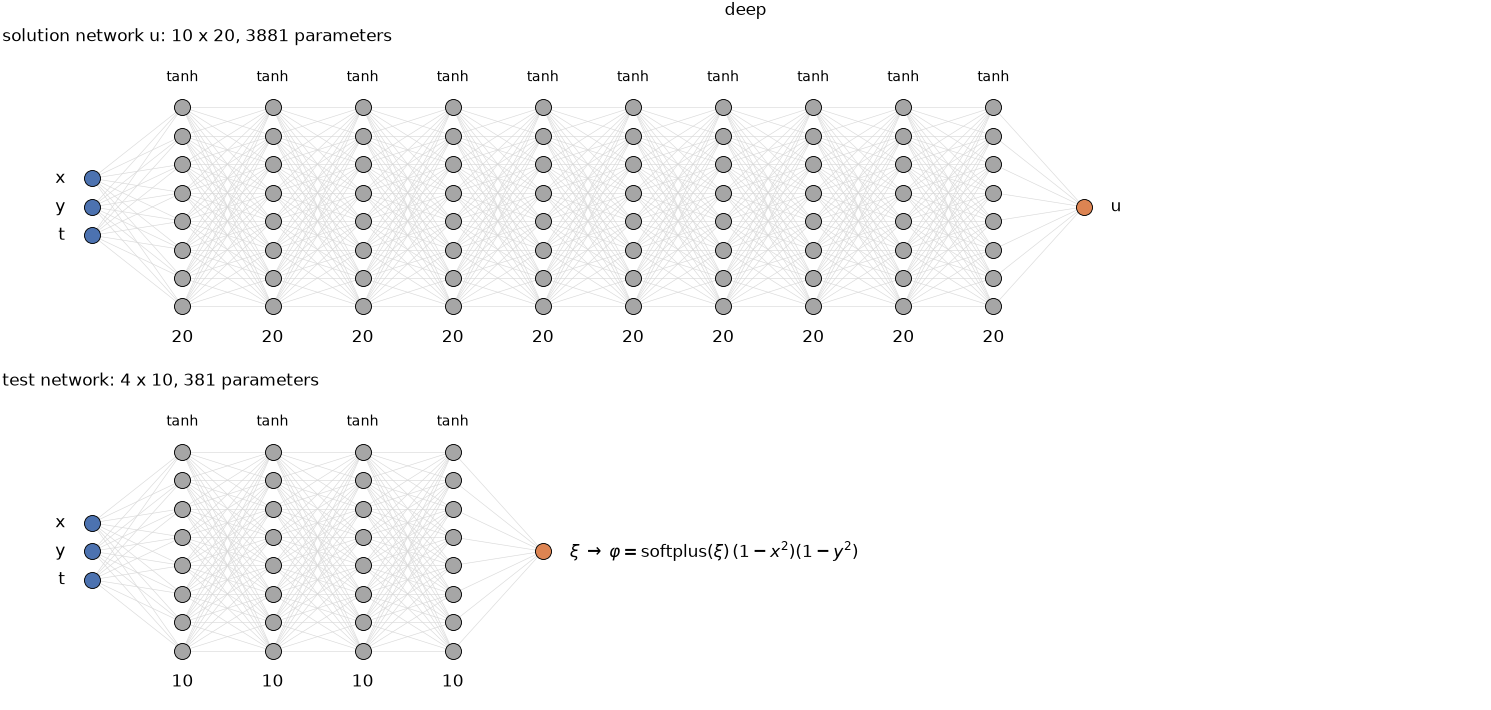

In [51]:
draw_architecture("deep", **architectures["deep"])

In [52]:
run_architecture("deep")

deep, seed 0  epoch   100  total 3.014e-01  weak 2.380e-02  adversary 2.352e-02  initial 2.645e-02  boundary 1.313e-03  [3 s]
deep, seed 0  epoch   200  total 7.295e-02  weak 1.280e-03  adversary 1.229e-03  initial 7.029e-03  boundary 1.381e-04  [5 s]
deep, seed 0  epoch   300  total 3.576e-02  weak 2.715e-04  adversary 2.534e-04  initial 3.455e-03  boundary 9.387e-05  [8 s]
deep, seed 0  epoch   400  total 2.248e-02  weak 2.608e-04  adversary 2.449e-04  initial 2.165e-03  boundary 5.744e-05  [11 s]
deep, seed 0  epoch   500  total 1.487e-02  weak 2.740e-04  adversary 2.587e-04  initial 1.433e-03  boundary 2.714e-05  [13 s]
deep, seed 0  epoch   600  total 1.021e-02  weak 3.354e-04  adversary 2.991e-04  initial 9.733e-04  boundary 1.417e-05  [16 s]
deep, seed 0  epoch   700  total 7.307e-03  weak 3.225e-04  adversary 2.895e-04  initial 6.875e-04  boundary 1.095e-05  [19 s]
deep, seed 0  epoch   800  total 5.907e-03  weak 4.156e-04  adversary 3.529e-04  initial 5.048e-04  boundary 4.428

### 5.4 wide

Sólo 2 capas pero 100 neuronas cada una: muchos parámetros sin profundidad.

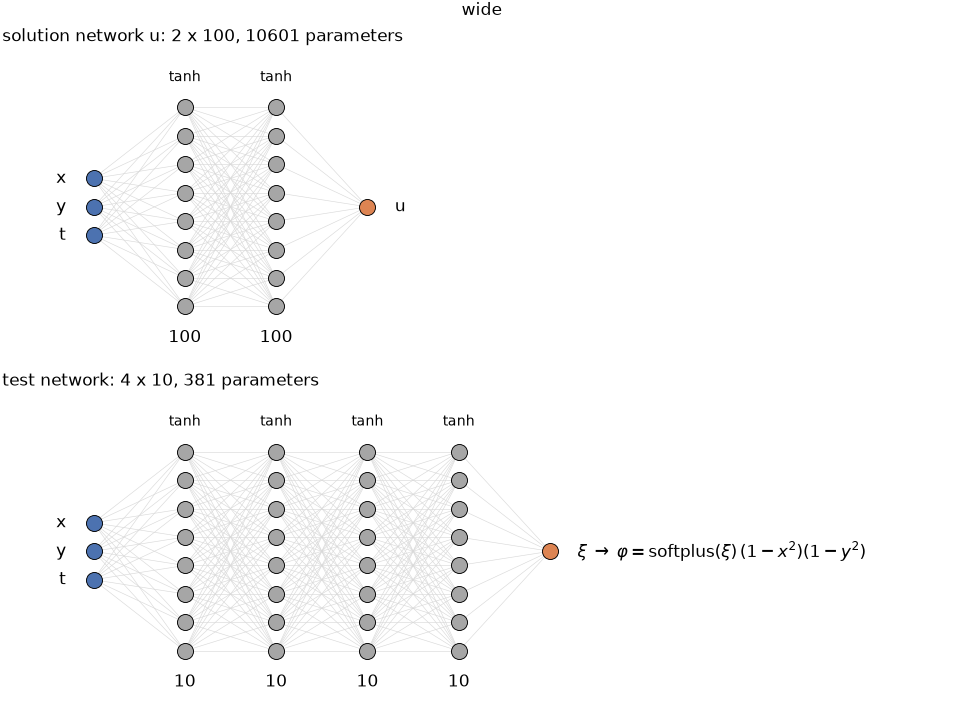

In [53]:
draw_architecture("wide", **architectures["wide"])

In [54]:
run_architecture("wide")

wide, seed 0  epoch   100  total 7.576e-01  weak 3.575e-02  adversary 3.481e-02  initial 6.855e-02  boundary 3.639e-03  [2 s]
wide, seed 0  epoch   200  total 6.917e-01  weak 2.462e-02  adversary 2.352e-02  initial 6.200e-02  boundary 4.714e-03  [4 s]
wide, seed 0  epoch   300  total 4.702e-01  weak 6.996e-03  adversary 6.656e-03  initial 4.387e-02  boundary 2.450e-03  [6 s]
wide, seed 0  epoch   400  total 2.284e-01  weak 1.610e-03  adversary 1.593e-03  initial 2.227e-02  boundary 4.144e-04  [9 s]
wide, seed 0  epoch   500  total 1.846e-01  weak 3.827e-03  adversary 3.328e-03  initial 1.760e-02  boundary 4.734e-04  [11 s]
wide, seed 0  epoch   600  total 1.556e-01  weak 2.165e-03  adversary 2.107e-03  initial 1.492e-02  boundary 4.263e-04  [13 s]
wide, seed 0  epoch   700  total 1.307e-01  weak 1.409e-03  adversary 1.343e-03  initial 1.259e-02  boundary 3.311e-04  [15 s]
wide, seed 0  epoch   800  total 1.081e-01  weak 8.160e-04  adversary 7.654e-04  initial 1.049e-02  boundary 2.366e

### 5.5 large

Unos 21 000 parámetros, diez veces el paper: la hipótesis "más es mejor" llevada lejos.

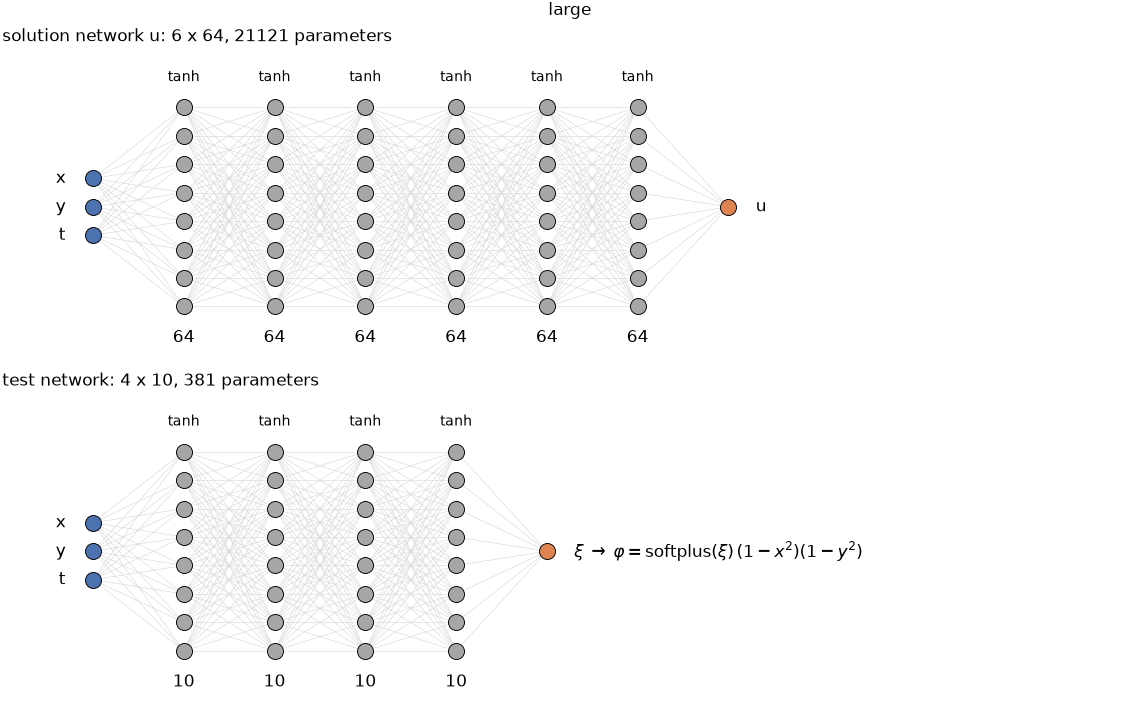

In [55]:
draw_architecture("large", **architectures["large"])

In [56]:
run_architecture("large")

large, seed 0  epoch   100  total 3.514e-01  weak 5.099e-03  adversary 4.890e-03  initial 3.353e-02  boundary 1.097e-03  [2 s]
large, seed 0  epoch   200  total 5.944e-02  weak 3.546e-04  adversary 3.353e-04  initial 5.752e-03  boundary 1.561e-04  [5 s]
large, seed 0  epoch   300  total 2.986e-02  weak 2.783e-04  adversary 2.625e-04  initial 2.852e-03  boundary 1.060e-04  [7 s]
large, seed 0  epoch   400  total 1.879e-02  weak 2.858e-04  adversary 2.638e-04  initial 1.803e-03  boundary 4.719e-05  [10 s]
large, seed 0  epoch   500  total 1.428e-02  weak 2.781e-04  adversary 2.653e-04  initial 1.332e-03  boundary 6.754e-05  [12 s]
large, seed 0  epoch   600  total 1.633e-02  weak 3.426e-04  adversary 3.115e-04  initial 1.170e-03  boundary 4.289e-04  [14 s]
large, seed 0  epoch   700  total 9.283e-03  weak 2.678e-04  adversary 2.499e-04  initial 7.839e-04  boundary 1.175e-04  [17 s]
large, seed 0  epoch   800  total 6.557e-03  weak 4.099e-04  adversary 3.497e-04  initial 5.919e-04  bounda

### 5.6 sine

Mismo tamaño que el paper pero con activación seno, la que usan De Ryck et al. para $u$.

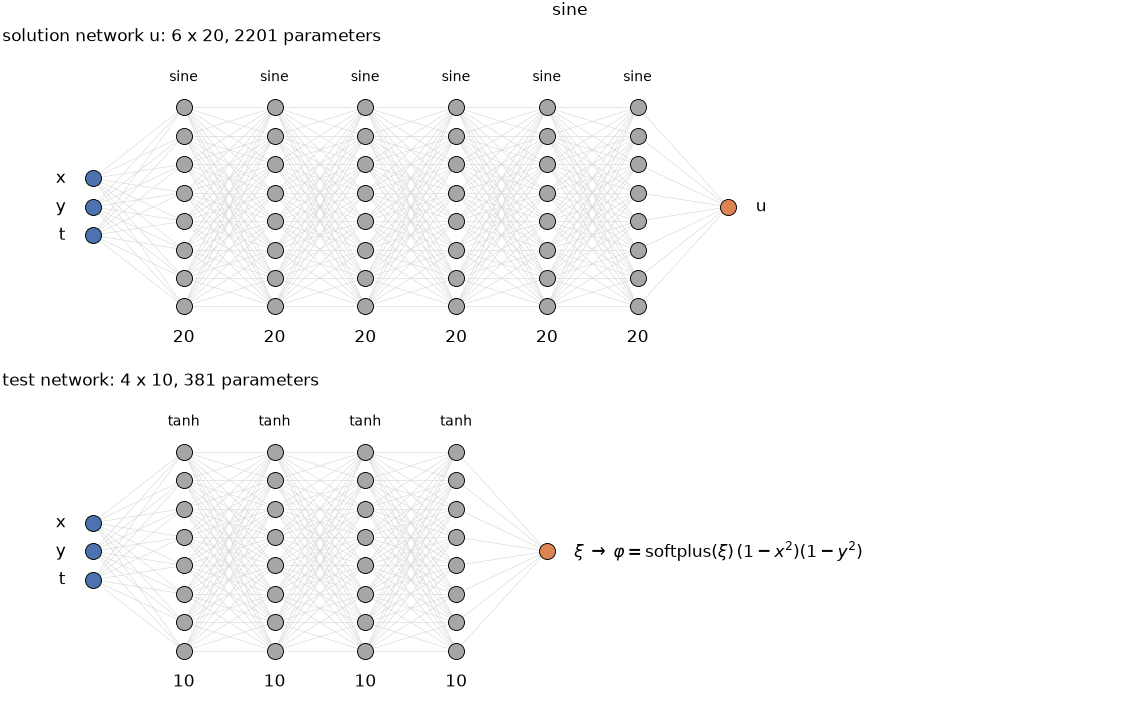

In [57]:
draw_architecture("sine", **architectures["sine"])

In [58]:
run_architecture("sine")

sine, seed 0  epoch   100  total 6.891e-01  weak 1.702e-02  adversary 1.659e-02  initial 6.322e-02  boundary 3.990e-03  [3 s]
sine, seed 0  epoch   200  total 5.593e-01  weak 7.520e-03  adversary 7.188e-03  initial 5.074e-02  boundary 4.442e-03  [5 s]
sine, seed 0  epoch   300  total 2.012e-01  weak 2.369e-03  adversary 2.301e-03  initial 1.934e-02  boundary 5.403e-04  [8 s]
sine, seed 0  epoch   400  total 1.200e-01  weak 2.643e-04  adversary 2.521e-04  initial 1.167e-02  boundary 3.083e-04  [10 s]
sine, seed 0  epoch   500  total 7.456e-02  weak 4.048e-04  adversary 3.867e-04  initial 7.218e-03  boundary 1.967e-04  [13 s]
sine, seed 0  epoch   600  total 4.808e-02  weak 2.520e-04  adversary 2.405e-04  initial 4.689e-03  boundary 9.343e-05  [15 s]
sine, seed 0  epoch   700  total 3.603e-02  weak 2.633e-04  adversary 2.470e-04  initial 3.500e-03  boundary 7.623e-05  [18 s]
sine, seed 0  epoch   800  total 2.747e-02  weak 3.188e-04  adversary 2.860e-04  initial 2.656e-03  boundary 5.864

### 5.7 weak adversary

La red $u$ del paper contra una $\varphi$ de 1 capa de 5 neuronas: ¿puede una adversaria tan simple encontrar violaciones?

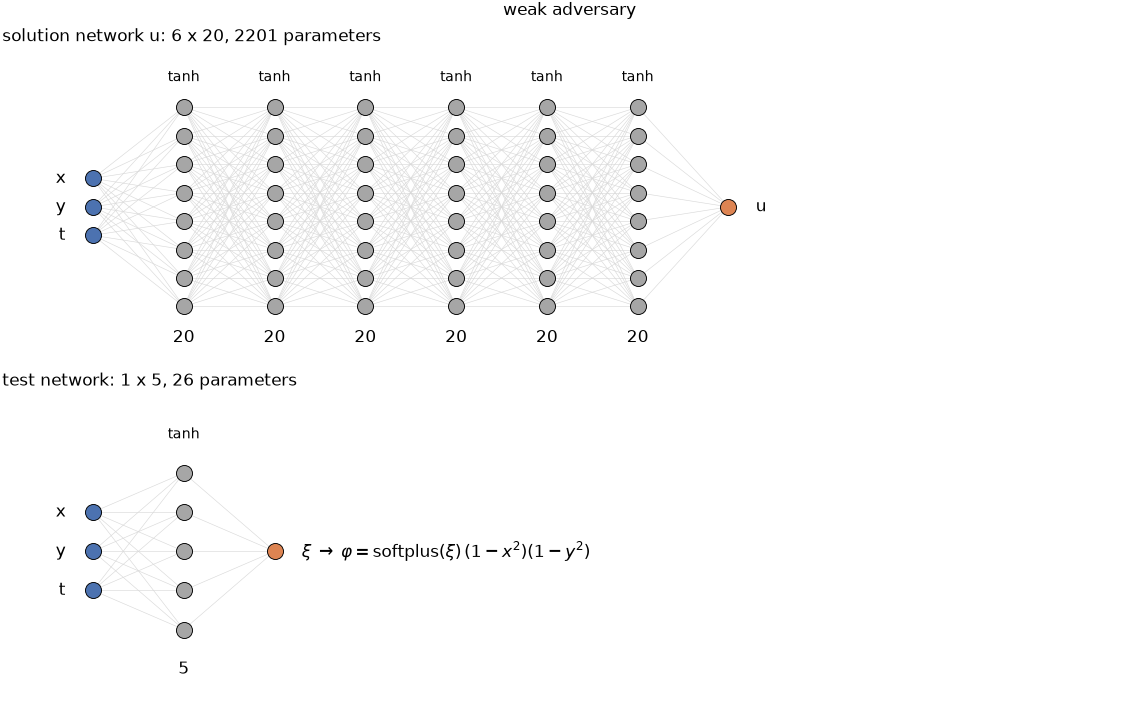

In [59]:
draw_architecture("weak adversary", **architectures["weak adversary"])

In [60]:
run_architecture("weak adversary")

weak adversary, seed 0  epoch   100  total 6.240e-01  weak 1.767e-02  adversary 1.754e-02  initial 5.688e-02  boundary 3.746e-03  [2 s]
weak adversary, seed 0  epoch   200  total 4.296e-01  weak 7.383e-03  adversary 7.289e-03  initial 3.942e-02  boundary 2.807e-03  [4 s]
weak adversary, seed 0  epoch   300  total 1.510e-01  weak 1.977e-03  adversary 1.960e-03  initial 1.458e-02  boundary 3.251e-04  [6 s]
weak adversary, seed 0  epoch   400  total 8.821e-02  weak 3.873e-04  adversary 3.784e-04  initial 8.556e-03  boundary 2.258e-04  [9 s]
weak adversary, seed 0  epoch   500  total 5.999e-02  weak 2.787e-04  adversary 2.723e-04  initial 5.818e-03  boundary 1.528e-04  [11 s]
weak adversary, seed 0  epoch   600  total 4.389e-02  weak 2.376e-04  adversary 2.338e-04  initial 4.243e-03  boundary 1.222e-04  [13 s]
weak adversary, seed 0  epoch   700  total 3.419e-02  weak 2.592e-04  adversary 2.553e-04  initial 3.287e-03  boundary 1.054e-04  [16 s]
weak adversary, seed 0  epoch   800  total 2.

### 5.8 strong adversary

La red $u$ del paper contra una $\varphi$ de 4 capas de 40, más grande que $u$: ¿la guía mejor o desbalancea el juego?

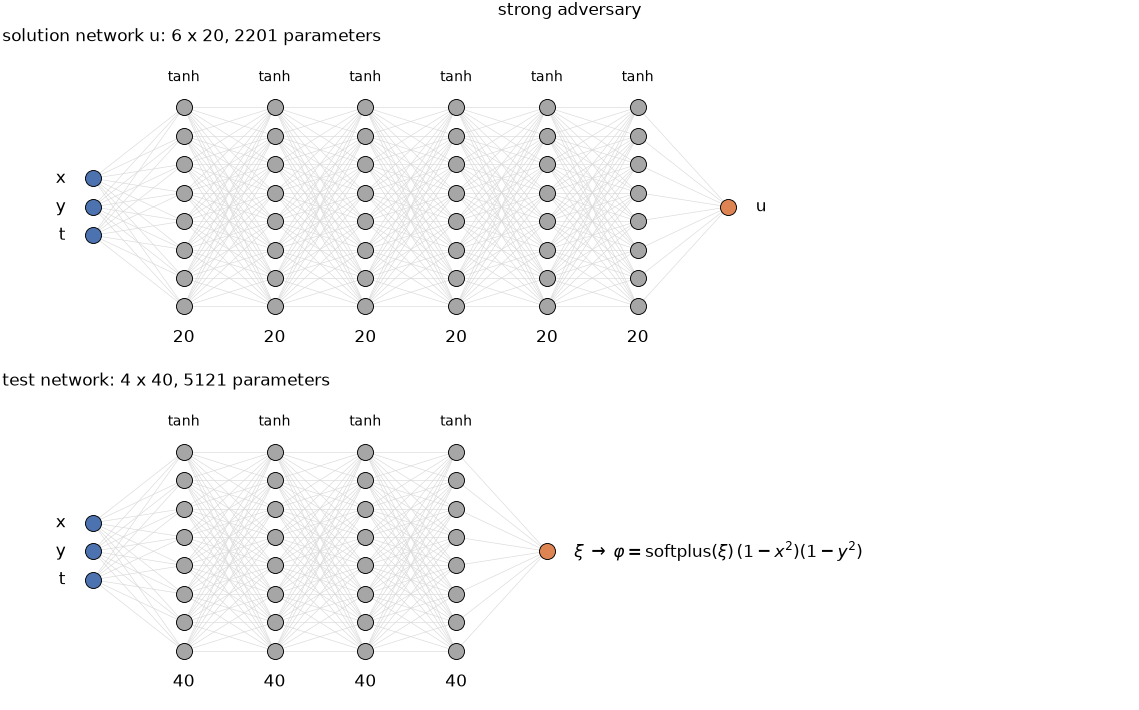

In [61]:
draw_architecture("strong adversary", **architectures["strong adversary"])

In [62]:
run_architecture("strong adversary")

strong adversary, seed 0  epoch   100  total 6.281e-01  weak 2.114e-02  adversary 2.074e-02  initial 5.701e-02  boundary 3.683e-03  [3 s]
strong adversary, seed 0  epoch   200  total 4.334e-01  weak 1.136e-02  adversary 1.078e-02  initial 3.945e-02  boundary 2.756e-03  [5 s]
strong adversary, seed 0  epoch   300  total 1.498e-01  weak 1.867e-03  adversary 1.778e-03  initial 1.446e-02  boundary 3.311e-04  [7 s]
strong adversary, seed 0  epoch   400  total 8.786e-02  weak 5.040e-04  adversary 4.834e-04  initial 8.527e-03  boundary 2.087e-04  [10 s]
strong adversary, seed 0  epoch   500  total 6.039e-02  weak 6.172e-04  adversary 5.982e-04  initial 5.832e-03  boundary 1.447e-04  [12 s]
strong adversary, seed 0  epoch   600  total 4.458e-02  weak 8.574e-04  adversary 7.203e-04  initial 4.252e-03  boundary 1.200e-04  [15 s]
strong adversary, seed 0  epoch   700  total 3.485e-02  weak 8.084e-04  adversary 6.234e-04  initial 3.300e-03  boundary 1.034e-04  [17 s]
strong adversary, seed 0  epoc

### 5.9 Resultados

Tabla con los parámetros de cada red, los errores relativos en $t = T$ (media ± desviación sobre
las 3 semillas) y el tiempo promedio por entrenamiento.

In [63]:
summary = {}
for name, runs in architecture_runs.items():
    errors = np.array([relative_errors(network) for network, history in runs])   # (n_semillas, 2)
    summary[name] = {
        "u_parameters": count_parameters(runs[0][0]),
        "test_parameters": runs[0][1]["test_parameters"],
        "l1_mean": errors[:, 0].mean(), "l1_std": errors[:, 0].std(),
        "l2_mean": errors[:, 1].mean(), "l2_std": errors[:, 1].std(),
        "seconds": np.mean([history["seconds"] for network, history in runs]),
    }

print(f"{'architecture':18s} {'u params':>9s} {'phi params':>10s} {'rel. L1':>17s} {'rel. L2':>17s} {'seconds':>8s}")
for name, row in summary.items():
    print(f"{name:18s} {row['u_parameters']:9d} {row['test_parameters']:10d} "
          f"{row['l1_mean']:8.4f} ± {row['l1_std']:6.4f} {row['l2_mean']:8.4f} ± {row['l2_std']:6.4f} "
          f"{row['seconds']:8.0f}")

architecture        u params phi params           rel. L1           rel. L2  seconds
tiny                     161        381   0.3356 ± 0.0278   0.3521 ± 0.0219       22
paper                   2201        381   0.0486 ± 0.0020   0.1499 ± 0.0090       24
deep                    3881        381   0.0182 ± 0.0021   0.1164 ± 0.0092       27
wide                   10601        381   0.0976 ± 0.0096   0.1513 ± 0.0057       21
large                  21121        381   0.0356 ± 0.0107   0.1404 ± 0.0179       24
sine                    2201        381   0.0638 ± 0.0177   0.1696 ± 0.0124       25
weak adversary          2201         26   0.0488 ± 0.0021   0.1490 ± 0.0102       21
strong adversary        2201       5121   0.0545 ± 0.0032   0.1589 ± 0.0035       24


#### Figura 13: error contra tamaño de la arquitectura

**Figura 13.** Error relativo $L^1$ en $t = T$ contra el número de parámetros de $u$ (eje x en
escala logarítmica); las barras son la desviación sobre las 3 semillas. La línea negra une el
barrido de tamaño con tanh (tiny → paper → deep → wide → large): **si la hipótesis es cierta, baja
de izquierda a derecha**. Los marcadores sueltos tienen el mismo $u$ que el paper y cambian otra
cosa (activación o tamaño de $\varphi$); van corridos un poco en x sólo para que no se tapen.

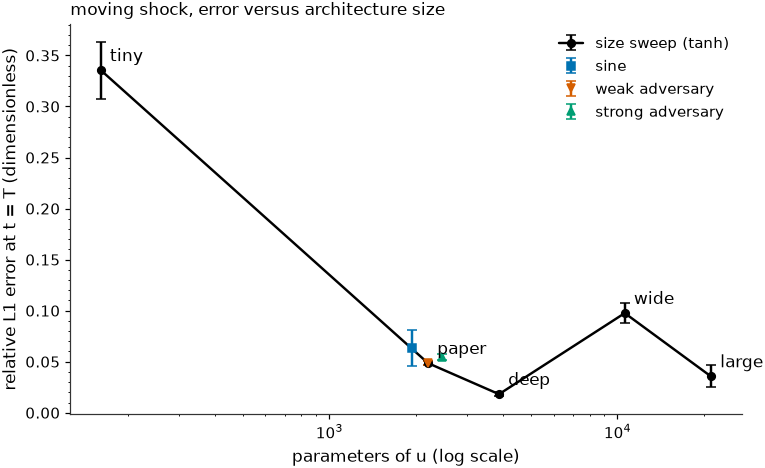

In [64]:
# Barrido de tamaño, ordenado por número de parámetros de u.
size_sweep = sorted(["tiny", "paper", "deep", "wide", "large"], key=lambda name: summary[name]["u_parameters"])

fig, ax = plt.subplots()
ax.errorbar([summary[name]["u_parameters"] for name in size_sweep],
            [summary[name]["l1_mean"] for name in size_sweep],
            yerr=[summary[name]["l1_std"] for name in size_sweep],
            color="black", marker="o", linestyle="-", capsize=3, label="size sweep (tanh)")
for name in size_sweep:
    ax.annotate(name, (summary[name]["u_parameters"], summary[name]["l1_mean"]),
                textcoords="offset points", xytext=(6, 6))

# Variantes con el mismo u que el paper: marcador distinto y un corrimiento pequeño en x.
variants = {"sine": ("s", 0.88), "weak adversary": ("v", 1.0), "strong adversary": ("^", 1.12)}
for name, (marker, shift) in variants.items():
    ax.errorbar(summary[name]["u_parameters"] * shift, summary[name]["l1_mean"], yerr=summary[name]["l1_std"],
                marker=marker, linestyle="none", capsize=3, label=name)

ax.set_xscale("log")
ax.set_xlabel("parameters of u (log scale)")
ax.set_ylabel("relative L1 error at t = T (dimensionless)")
ax.set_title("moving shock, error versus architecture size")
ax.legend()
plt.show()

#### Figura 14: cortes del barrido de u

**Figura 14.** Corte en $y = 0$ y $t = T$ de las arquitecturas de $u$ (semilla 0) contra la
exacta (negro). Se ve directamente qué tan empinado logra el salto cada red y dónde lo ubica.

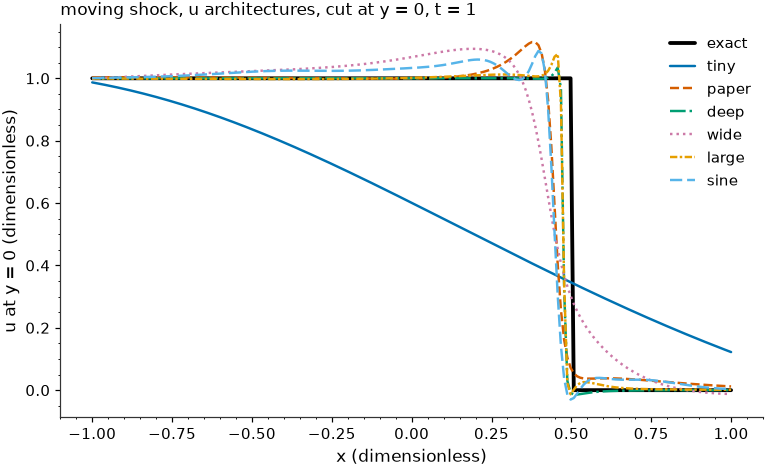

In [65]:
cut_line_styles = ["-", "--", "-.", ":", (0, (3, 1, 1, 1)), (0, (5, 2))]

fig, ax = plt.subplots()
ax.plot(x_axis, exact_solution(x_axis, T), color="black", linewidth=2.5, label="exact")
for name, line_style in zip(["tiny", "paper", "deep", "wide", "large", "sine"], cut_line_styles):
    network = architecture_runs[name][0][0]   # semilla 0
    u_cut = evaluate(network, x_axis, np.zeros_like(x_axis), np.full_like(x_axis, T))
    ax.plot(x_axis, u_cut, linestyle=line_style, label=name)
ax.set_xlabel("x (dimensionless)")
ax.set_ylabel("u at y = 0 (dimensionless)")
ax.set_title(f"moving shock, u architectures, cut at y = 0, t = {T}")
ax.legend()
plt.show()

#### Figura 15: cortes del barrido de φ

**Figura 15.** El mismo corte para el tamaño de la red test (semilla 0): misma $u$ del paper con
una $\varphi$ débil, la del paper y una fuerte. Si la adversaria débil no ve las violaciones, su
choque debería salir peor ubicado o más suave.

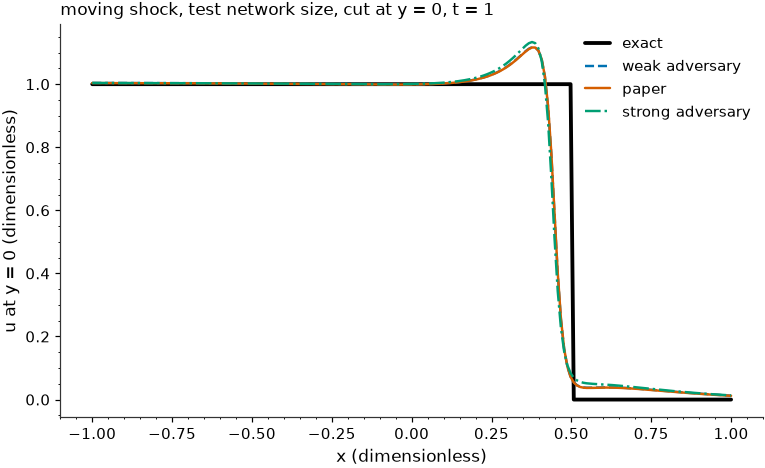

In [66]:
fig, ax = plt.subplots()
ax.plot(x_axis, exact_solution(x_axis, T), color="black", linewidth=2.5, label="exact")
for name, line_style in zip(["weak adversary", "paper", "strong adversary"], ["--", "-", "-."]):
    network = architecture_runs[name][0][0]   # semilla 0
    u_cut = evaluate(network, x_axis, np.zeros_like(x_axis), np.full_like(x_axis, T))
    ax.plot(x_axis, u_cut, linestyle=line_style, label=name)
ax.set_xlabel("x (dimensionless)")
ax.set_ylabel("u at y = 0 (dimensionless)")
ax.set_title(f"moving shock, test network size, cut at y = 0, t = {T}")
ax.legend()
plt.show()

## 6. Experimento 5: puntos de colocación

¿Ayuda poner más puntos donde está el choque? Hoy los 16 000 puntos interiores son uniformes:
la mayoría cae donde $u$ es constante y no hay nada que aprender.

**Estrategias que hay en la literatura:**

| Estrategia | Idea | Referencia | ¿Se corre? |
|---|---|---|---|
| uniforme aleatoria | la de siempre | — | sí (línea base) |
| cuasi-aleatoria (Sobol) | cubre el dominio sin huecos ni grumos (baja discrepancia), sin concentrar | Wu et al. 2023 | sí |
| conocimiento previo | más puntos donde se sabe que está el choque | Mao, Jagtap y Karniadakis 2020 | sí, como **oráculo** (usa la exacta $x = t/2$) |
| RAR | agregar puntos donde el residual es grande | Lu et al. 2021 (DeepXDE) | no, es casi igual a RAD |
| RAD | re-sortear con densidad $\propto$ indicador / media + 1 | Wu et al. 2023 | sí, con un indicador de choque |

**Por qué RAD no usa el residual aquí.** En la wPINN el residual es una integral contra
$\varphi$, no un número por punto. Como indicador de choque uso $|\partial u / \partial x|$ de la
red actual: es grande justo en el salto y no necesita conocer la exacta.

**Detalle clave: pesos de importancia.** El residual débil es $|D| \cdot \text{media}(\text{integrando})$,
un estimador Monte Carlo que sólo es correcto con puntos uniformes. Si los puntos salen con
densidad $p$, cada uno debe pesar $w = (1/|D|)/p$; si no, la integral queda sesgada hacia la zona
densa. Por eso la banda se corre **con y sin** pesos.

**Cómo se concentran los puntos.** Se sortea un pozo uniforme de 200 000 puntos, se evalúa una
densidad $f > 0$ en cada uno y se eligen 16 000 con probabilidad $\propto f$. El peso de cada punto
elegido es $w = \text{media}(f)/f$: si $f$ es constante, $w = 1$ y se recupera el caso uniforme.

**Qué espero:** band y RAD afilan el choque; band sin pesos lo corre de lugar, porque cambia la
integral; Sobol se parece a uniform pero con menos varianza entre semillas.

Todas con L0, la arquitectura del paper y 3 semillas (15 entrenamientos).

### 6.0 Configuración del experimento

In [67]:
# Usa seeds y relative_errors de la sección 5.0 (basta correr esa celda, no los entrenamientos).
n_pool = 200_000        # tamaño del pozo uniforme del que se eligen los puntos
band_amplitude = 10.0   # el centro de la banda es 1 + 10 = 11 veces más denso que lejos del choque
band_width = 0.1        # sigma de la banda en x


def sample_sobol(u_network):
    # Cuasi-aleatorio: cubre la caja de forma pareja. No concentra nada, así que pesos 1.
    # u_network no se usa; está para que todos los muestreadores se llamen igual.
    engine_seed = int(torch.randint(0, 2**31 - 1, (1,)))   # cambia con la semilla del entrenamiento
    engine = torch.quasirandom.SobolEngine(dimension=3, scramble=True, seed=engine_seed)
    unit_points = engine.draw(n_interior)                 # en [0, 1)^3
    lower = torch.tensor([x_min, y_min, 0.0])
    upper = torch.tensor([x_max, y_max, T])
    points = (lower + (upper - lower) * unit_points).to(device)
    return points.requires_grad_(True), torch.ones(n_interior, 1, device=device)


def sample_by_density(density_function, use_weights=True):
    # Elige n_interior puntos de un pozo uniforme con probabilidad proporcional a density_function.
    pool = sample_interior_points(n_pool)
    density = density_function(pool).flatten()            # (n_pool,), valores > 0
    chosen = torch.multinomial(density, n_interior, replacement=False)
    points = pool[chosen].detach().clone()
    if use_weights:
        # Peso de importancia w = media(f) / f: devuelve la integral a su valor correcto.
        # Como se elige sin reemplazo un 8 % del pozo, la media de w se desvía un poco de 1;
        # se normaliza a media 1 (estimador de importancia autonormalizado).
        weights = (density.mean() / density[chosen]).reshape(-1, 1)
        weights = weights / weights.mean()
    else:
        # Sin corregir: la zona densa pesa más en la integral, así que la pérdida cambia.
        weights = torch.ones(n_interior, 1, device=device)
    return points.requires_grad_(True), weights.detach()


def band_density(points):
    # Oráculo: banda gaussiana alrededor del choque exacto x = t/2. Usa la exacta, así que es
    # "trampa": sirve como referencia de lo mejor que se logra concentrando puntos.
    x = points[:, 0:1]
    t = points[:, 2:3]
    return 1.0 + band_amplitude * torch.exp(-((x - shock_speed * t) ** 2) / (2 * band_width**2))


def gradient_density(u_network):
    # RAD con indicador de choque: f = 1 + |u_x| / media|u_x|, con la u actual. No usa la exacta.
    def density(points):
        points = points.clone().requires_grad_(True)
        u = u_network(points)
        u_x = torch.autograd.grad(u.sum(), points)[0][:, 0:1].abs()
        return (1.0 + u_x / u_x.mean()).detach()
    return density


# Estrategia: nombre -> argumentos de train_wpinn. Los lambda adaptan cada muestreador a la
# forma sampler(u_network) que espera train_wpinn.
sampling_strategies = {
    "uniform": dict(),
    "sobol": dict(sampler=sample_sobol),
    "band (weighted)": dict(sampler=lambda u_network: sample_by_density(band_density)),
    "band (unweighted)": dict(sampler=lambda u_network: sample_by_density(band_density, use_weights=False)),
    # RAD re-sortea cada 100 épocas: al principio la red es aleatoria y su |u_x| no marca nada.
    "adaptive (RAD)": dict(sampler=lambda u_network: sample_by_density(gradient_density(u_network)),
                           resample_every=100),
}
sampling_runs = {}   # nombre -> lista de (red, historia), una por semilla


def run_sampling(name):
    # Entrena con la estrategia de muestreo y las 3 semillas, y guarda los resultados.
    sampling_runs[name] = []
    for seed in seeds:
        network, history = train_wpinn(level=0, seed=seed, label=f"{name}, seed {seed}", **sampling_strategies[name])
        sampling_runs[name].append((network, history))

### 6.1 uniform

La línea base: puntos uniformes, igual que el paper, con las mismas 3 semillas.

In [68]:
run_sampling("uniform")

uniform, seed 0  epoch   100  total 6.244e-01  weak 1.784e-02  adversary 1.736e-02  initial 5.690e-02  boundary 3.755e-03  [2 s]
uniform, seed 0  epoch   200  total 4.305e-01  weak 8.537e-03  adversary 8.191e-03  initial 3.939e-02  boundary 2.807e-03  [5 s]
uniform, seed 0  epoch   300  total 1.505e-01  weak 1.876e-03  adversary 1.853e-03  initial 1.454e-02  boundary 3.273e-04  [7 s]
uniform, seed 0  epoch   400  total 8.808e-02  weak 3.967e-04  adversary 3.839e-04  initial 8.540e-03  boundary 2.286e-04  [10 s]
uniform, seed 0  epoch   500  total 5.991e-02  weak 2.754e-04  adversary 2.596e-04  initial 5.811e-03  boundary 1.526e-04  [12 s]
uniform, seed 0  epoch   600  total 4.385e-02  weak 2.567e-04  adversary 2.451e-04  initial 4.236e-03  boundary 1.237e-04  [15 s]
uniform, seed 0  epoch   700  total 3.418e-02  weak 2.819e-04  adversary 2.622e-04  initial 3.291e-03  boundary 9.828e-05  [17 s]
uniform, seed 0  epoch   800  total 2.785e-02  weak 3.350e-04  adversary 2.988e-04  initial 2

### 6.2 sobol

Puntos de Sobol: la misma densidad uniforme pero repartida sin huecos ni grumos. No concentra; mide cuánto importa el ruido del sorteo.

In [69]:
run_sampling("sobol")

sobol, seed 0  epoch   100  total 6.206e-01  weak 1.458e-02  adversary 1.414e-02  initial 5.697e-02  boundary 3.635e-03  [3 s]
sobol, seed 0  epoch   200  total 4.297e-01  weak 7.158e-03  adversary 6.825e-03  initial 3.952e-02  boundary 2.738e-03  [5 s]
sobol, seed 0  epoch   300  total 1.516e-01  weak 2.247e-03  adversary 2.220e-03  initial 1.463e-02  boundary 3.107e-04  [7 s]
sobol, seed 0  epoch   400  total 8.822e-02  weak 3.036e-04  adversary 2.960e-04  initial 8.557e-03  boundary 2.340e-04  [10 s]
sobol, seed 0  epoch   500  total 5.986e-02  weak 1.380e-04  adversary 1.340e-04  initial 5.814e-03  boundary 1.580e-04  [12 s]
sobol, seed 0  epoch   600  total 4.352e-02  weak 7.543e-05  adversary 7.448e-05  initial 4.217e-03  boundary 1.270e-04  [15 s]
sobol, seed 0  epoch   700  total 3.381e-02  weak 5.010e-05  adversary 4.966e-05  initial 3.269e-03  boundary 1.066e-04  [18 s]
sobol, seed 0  epoch   800  total 2.737e-02  weak 1.558e-05  adversary 1.498e-05  initial 2.652e-03  bounda

### 6.3 band (weighted)

Banda alrededor del choque exacto (oráculo), con pesos de importancia: más puntos en el choque sin cambiar la integral.

In [70]:
run_sampling("band (weighted)")

band (weighted), seed 0  epoch   100  total 6.208e-01  weak 1.477e-02  adversary 1.452e-02  initial 5.701e-02  boundary 3.592e-03  [3 s]
band (weighted), seed 0  epoch   200  total 4.312e-01  weak 7.809e-03  adversary 7.637e-03  initial 3.961e-02  boundary 2.736e-03  [5 s]
band (weighted), seed 0  epoch   300  total 1.539e-01  weak 3.421e-03  adversary 3.391e-03  initial 1.472e-02  boundary 3.217e-04  [8 s]
band (weighted), seed 0  epoch   400  total 8.936e-02  weak 7.394e-04  adversary 7.281e-04  initial 8.595e-03  boundary 2.666e-04  [10 s]
band (weighted), seed 0  epoch   500  total 6.048e-02  weak 2.694e-04  adversary 2.459e-04  initial 5.835e-03  boundary 1.861e-04  [13 s]
band (weighted), seed 0  epoch   600  total 4.397e-02  weak 1.032e-04  adversary 9.749e-05  initial 4.233e-03  boundary 1.539e-04  [16 s]
band (weighted), seed 0  epoch   700  total 3.414e-02  weak 4.629e-05  adversary 3.995e-05  initial 3.279e-03  boundary 1.307e-04  [18 s]
band (weighted), seed 0  epoch   800 

### 6.4 band (unweighted)

La misma banda **sin** pesos: la integral queda sesgada hacia el choque. Muestra por qué hacen falta los pesos.

In [71]:
run_sampling("band (unweighted)")

band (unweighted), seed 0  epoch   100  total 6.296e-01  weak 1.831e-02  adversary 1.824e-02  initial 5.641e-02  boundary 4.714e-03  [3 s]
band (unweighted), seed 0  epoch   200  total 4.399e-01  weak 1.234e-02  adversary 1.231e-02  initial 4.025e-02  boundary 2.501e-03  [5 s]
band (unweighted), seed 0  epoch   300  total 1.962e-01  weak 4.368e-02  adversary 3.306e-02  initial 1.503e-02  boundary 2.190e-04  [8 s]
band (unweighted), seed 0  epoch   400  total 1.046e-01  weak 1.553e-02  adversary 1.515e-02  initial 8.743e-03  boundary 1.634e-04  [10 s]
band (unweighted), seed 0  epoch   500  total 7.730e-02  weak 1.493e-02  adversary 1.434e-02  initial 5.980e-03  boundary 2.569e-04  [13 s]
band (unweighted), seed 0  epoch   600  total 8.309e-02  weak 3.810e-02  adversary 2.899e-02  initial 4.406e-03  boundary 9.277e-05  [15 s]
band (unweighted), seed 0  epoch   700  total 5.458e-02  weak 1.867e-02  adversary 1.635e-02  initial 3.533e-03  boundary 5.843e-05  [17 s]
band (unweighted), seed

### 6.5 adaptive (RAD)

Adaptativa: cada 100 épocas los puntos se re-sortean donde $|u_x|$ de la red actual es grande. Es la única que concentra sin conocer la exacta.

In [72]:
run_sampling("adaptive (RAD)")

adaptive (RAD), seed 0  epoch   100  total 6.190e-01  weak 1.308e-02  adversary 1.269e-02  initial 5.696e-02  boundary 3.626e-03  [2 s]
adaptive (RAD), seed 0  epoch   200  total 4.300e-01  weak 7.238e-03  adversary 6.847e-03  initial 3.956e-02  boundary 2.716e-03  [5 s]
adaptive (RAD), seed 0  epoch   300  total 1.546e-01  weak 4.842e-03  adversary 4.807e-03  initial 1.466e-02  boundary 3.074e-04  [7 s]
adaptive (RAD), seed 0  epoch   400  total 8.977e-02  weak 1.519e-03  adversary 1.457e-03  initial 8.571e-03  boundary 2.543e-04  [10 s]
adaptive (RAD), seed 0  epoch   500  total 6.061e-02  weak 3.562e-04  adversary 3.260e-04  initial 5.834e-03  boundary 1.916e-04  [12 s]
adaptive (RAD), seed 0  epoch   600  total 4.467e-02  weak 6.823e-04  adversary 6.478e-04  initial 4.240e-03  boundary 1.587e-04  [15 s]
adaptive (RAD), seed 0  epoch   700  total 3.488e-02  weak 4.675e-04  adversary 4.434e-04  initial 3.294e-03  boundary 1.476e-04  [17 s]
adaptive (RAD), seed 0  epoch   800  total 2

### 6.6 Resultados

#### Figura 16: concentración de los puntos de colocación

**Figura 16.** Histograma de los puntos interiores con los que terminó cada entrenamiento
(semilla 0), proyectados en el plano $(x, t)$: $y$ no influye porque el dato no depende de él.
Todos los paneles comparten la escala de color. La línea blanca discontinua es el choque exacto
$x = t/2$. En RAD se ven los puntos del último re-sorteo, es decir, dónde terminó creyendo la red
que está el choque.

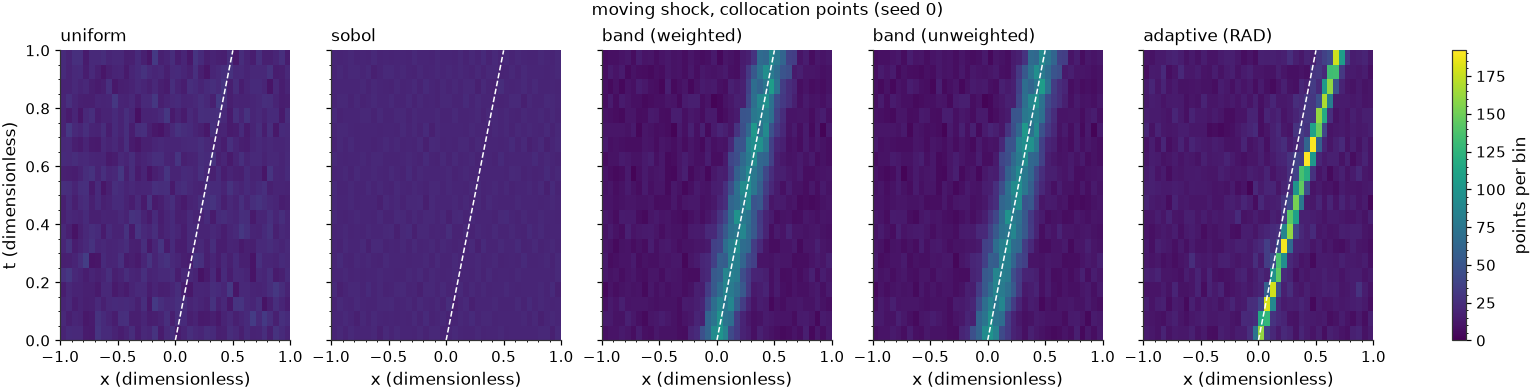

In [73]:
x_bins = np.linspace(x_min, x_max, 41)
t_bins = np.linspace(0.0, T, 21)
final_points = {name: runs[0][1]["interior_points"].numpy() for name, runs in sampling_runs.items()}

# Misma escala de color en todos los paneles: el máximo de puntos por celda entre todos.
counts_max = max(np.histogram2d(points[:, 0], points[:, 2], bins=[x_bins, t_bins])[0].max()
                 for points in final_points.values())

fig, axes = plt.subplots(1, len(final_points), figsize=(14.0, 3.6), sharey=True)
for ax, (name, points) in zip(axes, final_points.items()):
    *_, image = ax.hist2d(points[:, 0], points[:, 2], bins=[x_bins, t_bins],
                          cmap="viridis", vmin=0, vmax=counts_max)
    ax.plot([0.0, shock_speed * T], [0.0, T], color="white", linestyle="--", linewidth=1.0)
    ax.set_title(name)
    ax.set_xlabel("x (dimensionless)")
axes[0].set_ylabel("t (dimensionless)")
fig.colorbar(image, ax=axes, label="points per bin")
fig.suptitle("moving shock, collocation points (seed 0)")
plt.show()

#### Figura 17: error por estrategia de muestreo

**Figura 17.** Error relativo $L^1$ en $t = T$ por estrategia (media ± desviación sobre las 3
semillas). El eje parte de cero para que la altura de las barras sea comparable. Arriba se
imprime la tabla con los errores $L^1$ y $L^2$ y el tiempo promedio.

strategy                       rel. L1           rel. L2  seconds
uniform                0.0486 ± 0.0020   0.1499 ± 0.0090       26
sobol                  0.0326 ± 0.0083   0.0815 ± 0.0107       25
band (weighted)        0.0670 ± 0.0057   0.2127 ± 0.0139       26
band (unweighted)      0.2145 ± 0.0084   0.4291 ± 0.0022       25
adaptive (RAD)         0.1677 ± 0.0104   0.4020 ± 0.0151       25


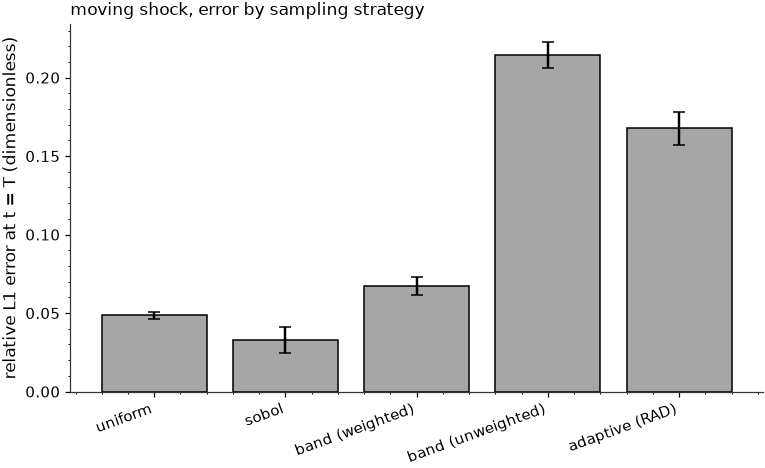

In [74]:
sampling_summary = {}
for name, runs in sampling_runs.items():
    errors = np.array([relative_errors(network) for network, history in runs])   # (n_semillas, 2)
    sampling_summary[name] = {
        "l1_mean": errors[:, 0].mean(), "l1_std": errors[:, 0].std(),
        "l2_mean": errors[:, 1].mean(), "l2_std": errors[:, 1].std(),
        "seconds": np.mean([history["seconds"] for network, history in runs]),
    }

print(f"{'strategy':20s} {'rel. L1':>17s} {'rel. L2':>17s} {'seconds':>8s}")
for name, row in sampling_summary.items():
    print(f"{name:20s} {row['l1_mean']:8.4f} ± {row['l1_std']:6.4f} "
          f"{row['l2_mean']:8.4f} ± {row['l2_std']:6.4f} {row['seconds']:8.0f}")

names = list(sampling_summary)
positions = np.arange(len(names))
fig, ax = plt.subplots()
ax.bar(positions, [sampling_summary[name]["l1_mean"] for name in names],
       yerr=[sampling_summary[name]["l1_std"] for name in names],
       capsize=4, color="0.65", edgecolor="black")
ax.set_xticks(positions)
ax.set_xticklabels(names, rotation=20, ha="right")
ax.set_ylim(bottom=0.0)
ax.set_ylabel("relative L1 error at t = T (dimensionless)")
ax.set_title("moving shock, error by sampling strategy")
plt.show()

#### Figura 18: cortes por estrategia de muestreo

**Figura 18.** Corte en $y = 0$ y $t = T$ de cada estrategia (semilla 0) contra la exacta
(negro). Aquí se ve si concentrar puntos afila el salto y si la banda sin pesos lo corre de lugar.

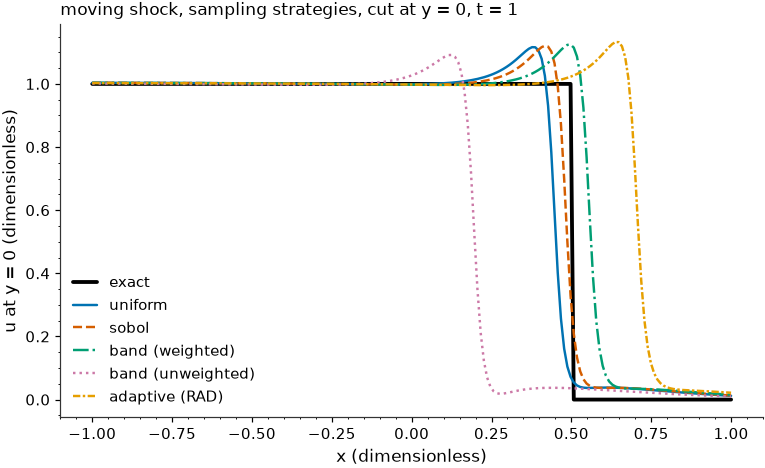

In [75]:
fig, ax = plt.subplots()
ax.plot(x_axis, exact_solution(x_axis, T), color="black", linewidth=2.5, label="exact")
for (name, runs), line_style in zip(sampling_runs.items(), ["-", "--", "-.", ":", (0, (3, 1, 1, 1))]):
    network = runs[0][0]   # semilla 0
    u_cut = evaluate(network, x_axis, np.zeros_like(x_axis), np.full_like(x_axis, T))
    ax.plot(x_axis, u_cut, linestyle=line_style, label=name)
ax.set_xlabel("x (dimensionless)")
ax.set_ylabel("u at y = 0 (dimensionless)")
ax.set_title(f"moving shock, sampling strategies, cut at y = 0, t = {T}")
ax.legend()
plt.show()